# Progetto Introduzione alla Programmazione

## *Immigrazione e rappresentazione mediatica: un'analisi delle comunità straniere nella stampa italiana*

### *Alice Somma, Flavia Frezzini, Micol Mancinelli*

##Introduzione
Il presente progetto si propone di indagare tre questioni inerenti al rapporto tra immigrazione e rappresentazione di comunità straniere nei media italiani attraverso l'utilizzo di dati ISTAT e articoli di giornale provenienti dal quotidiano *La Repubblica*.

Le questioni su cui ci si concentrerà in questo lavoro sono le seguenti:
- **Prima questione**: si indagherà se i media tendono a sovra-rappresentare o a sotto-rappresentare specifiche comunità straniere rispetto alla loro reale presenza sul territorio italiano.
- **Seconda questione**: ci si focalizzerà su tre eventi specifici nell'arco temporale 2014-2018 e si analizzerà la variazione (o la non-variazione) degli articoli in prossimità di tali eventi.
- **Terza questione**: si cercherà di comprendere se, quando si parla di specifiche nazionalità, vi sono alcune parole chiave che tendono a ricorrere.

# Prima questione: i media tendono a sovra-rappresentare o a sotto-rappresentare specifiche comunità razzializzate rispetto alla loro presenza reale sul territorio?

## Importazione
Importiamo le librerie e i moduli che utilizzeremo nel corso del progetto. In particolare:
- `pandas` e `numpy` per la manipolazione e l'analisi dei dataset.
- `re` per l'estrazione di pattern tramite espressioni regolari.
- `matplotlib`e `seaborn` per la visualizzazione grafica dei risultati.

In [ ]:
import os
import pandas as pd
import re
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

## Caricamento dei Dataset

In questa fase carichiamo i Dataset necessari per il lavoro:

- *`elenco_comuni.csv`*: mappa ogni comune italiano alla relativa provincia, regione e ripartizione geografica. Usiamo `dtype={"Codice Istat": str}` per non perdere gli zeri iniziali dei codici.

- *`repubblica.csv`*: contiene il corpus degli articoli di giornale estratti dal quotidiano *La Repubblica* (dataset Change-IT).

- *Dati ISTAT sulla cittadinanza*: 24 file che carichiamo con un ciclo for, filtrando solo i file che contengono "cittadinanza" nel nome (escludendo quindi i file sui dati di nascita), e li uniamo in un unico DataFrame `df_cittadinanza` con `pd.concat`.
Abbiamo scelto di utilizzare i dati relativi alla cittadinanza e non alla nascita per coerenza con il linguaggio mediatico (spesso i termini relativi alla nazionalità delle persone si riferiscono alla cittadinanza percepita o ufficiale, non al luogo di nascita) e per includere le persone di seconda generazione (che spesso vengono identificate a prescindere con la nazionalità dei genitori).

In [ ]:
base_path = "."
df_comuni = pd.read_csv(os.path.join(base_path, "data/istat/comuni/elenco_comuni.csv"), sep=",", dtype={"Codice Istat": str})
df_articoli = pd.read_csv(os.path.join(base_path, "data/CHANGE-it/repubblica.csv"))

# uniamo i DataFrame di dati_cittadinanza
folder_path = os.path.join(base_path, "data/istat/Dati_RCS")
lista_df = []

for file_name in os.listdir(folder_path):
    file_path = os.path.join(folder_path, file_name)
    if not os.path.isfile(file_path): # se è una cartella non la calcola e prosegue
        continue
    if "cittadinanza" in file_name:
        df_temp = pd.read_csv(
            file_path,
            sep=";",
            dtype={
                "Codice Istat": str,
                "Codice stato di cittadinanza/nascita": str
            }
        )
        lista_df.append(df_temp)

df_cittadinanza = pd.concat(lista_df, ignore_index=True) # concateniamo tutti i file

## Estrazione delle date dagli URL

Estraiamo le date dagli URL per datare gli articoli di giornale e poter svolgere le successive analisi temporali.

Estraiamo anno, mese e giorno direttamente dall'URL con una espressione regolare, e li salviamo come tre nuove colonne (Anno, Mese, Giorno) nel DataFrame degli articoli. La funzione `estrai_data_url` gestisce anche i casi in cui l'estrazione non riesce:
- se l'URL è mancante (non è una stringa), restituisce subito `None` per tutti e tre i valori.
- se l'URL è presente ma non contiene una data nel formato atteso, la ricerca con la regex non trova corrispondenze e restituisce comunque `None, None, None`.

In [ ]:
def estrai_data_url (url):
    if not isinstance(url, str):
        return None, None, None

    regex_data = r'/(\d{4})/(\d{2})/(\d{2})/'
    match = re.search(regex_data, url)
    if match:
        anno = int(match.group(1))
        mese = int(match.group(2))
        giorno = int(match.group(3))

        return anno, mese, giorno
    else:
        return None, None, None

array_url = df_articoli["url"].to_numpy() # trasformiamo gli URL in array numpy
estrai_array = np.vectorize(estrai_data_url) # applichiamo la funzione creata
anni, mesi, giorni = estrai_array(array_url) # estraiamo anni, mesi, giorni utilizzando gli array

df_articoli["Anno"] = anni
df_articoli["Mese"] = mesi
df_articoli["Giorno"] = giorni

df_articoli[["url", "Anno", "Mese", "Giorno"]].head()

,url,Anno,Mese,Giorno
0,NaN,None,None,None
1,http://www.repubblica.it/ambiente/2016/10/02/n...,2016,10,2
2,http://www.repubblica.it/cultura/2017/06/20/ne...,2017,6,20
3,http://www.repubblica.it/politica/2014/07/11/n...,2014,7,11
4,http://www.repubblica.it/cronaca/2014/08/16/ne...,2014,8,16


## Scelta delle nazionalità
Le 5 nazionalità scelte:
- **Marocco**: tra le comunità più presenti in Italia, fortemente collegata dai media ai temi di sicurezza e migrazione.
- **Romania**: comunità numericamente molto ampia.
- **Nigeria**: tra le comunità che maggiormente rappresentano la classica percezione dell'immigrazione legata agli sbarchi e all'asilo politico.
- **Cina**: gruppo ad alta presenza, ma spesso associato a narrazioni mediatiche totalmente diverse (lavoro, economia, comunità "chiuse") rispetto alle tre precedenti.
- **Francia**: gruppo di controllo, da confrontare con le altre nazionalità per rivelare se esista una discrepanza di razzializzazione nei media italiani.

Dopo aver scelto le 5 nazionalità, abbiamo creato tre strutture dati fondamentali per la successiva fase di filtraggio:
- `dizionario_nazionalita`: un dizionario con le varianti morfologiche di ogni nazionalità.
- `parole_immigrazione`: un insieme di parole utile per individuare gli articoli di giornale che trattano specificatamente di temi di immigrazione.
- `falsi_positivi`: un insieme di parole che costituisce dei possibili falsi positivi e che saranno quindi da escludere in fase di euristica.

La scelta delle parole da inserire nei falsi positivi è avvenuta manualmente. Questo insieme è necessario per escludere dagli articoli che verranno presi in esame quelli in cui vi sono citate le nazionalità, ma i quali si riferiscono a temi culturali, sportivi, economici o gastronomici non attinenti al tema migratorio.

In [ ]:
paesi_selezionati = ["Marocco", "Romania", "Cina", "Nigeria", "Francia"]

dizionario_nazionalita = {
    "Marocco": {"marocchino", "marocchina", "marocchini", "marocchine"},
    "Romania": {"rumeno", "rumena", "rumeni", "rumene", "romeno", "romena", "romeni", "romene"},
    "Cina": {"cinese", "cinesi"},
    "Nigeria": {"nigeriano", "nigeriana", "nigeriani", "nigeriane"},
    "Francia": {"francese", "francesi"}
    }

parole_immigrazione = {"immigrato", "immigrati", "immigrata", "immigrate",
    "migrante", "migranti", "straniero", "stranieri", "straniera", "straniere",
    "clandestino", "clandestini", "profugo", "profugi", "rifugiato", "rifugiati",
    "sbarchi", "sbarco", "asilo", "rimpatrio", "rimpatri",
    "accoglienza","barcone", "barconi", "cie", "cara"
    }

falsi_positivi = {"lingua", "corso", "scuola", "cucina", "presidente", "governo", "ambasciata", "macron",
                  "autorità", "ristorante", "capodanno", "muro", "ristoranti", "prodotti"}

## Fase di pre-processing e tokenizzazione

- **Pre-processing**: in questa fase abbiamo unito il titolo dell'articolo (`headline`) al testo (`full_text`) così da tokenizzare gli articoli nella loro interezza. Abbiamo utilizzato il metodo `.fillna(' ')` in modo che i possibili valori nulli nel DataFrame fossero sostituiti con uno spazio vuoto senza causare la perdita dell'intero articolo. Abbiamo quindi creato una nuova colonna nel DataFrame `df_articoli` con il testo completo.

- **Tokenizzazione**: in questa fase ci siamo assicurate che tutto il testo venisse trattato come una stringa, lo abbiamo convertito in minuscolo per rendere l'analisi case-insensitive e abbiamo utilizzato un'espressione regolare per estrarre le sequenze di caratteri alfanumerici escludendo i caratteri di spaziatura e punteggiatura.

Abbiamo infine creato una nuova colonna all'interno del DataFrame `df_articoli` con il testo tokenizzato.

In [ ]:
df_articoli["testo_completo"] = df_articoli["headline"].fillna('') + ' ' + df_articoli['full_text'].fillna(' ')

df_articoli["tokens"] = (
    df_articoli["testo_completo"]
    .astype(str)
    .str.lower()
    .str.findall(r"\w+"))

# vediamo un'anteprima delle prime 3 righe per verificare il risultato
df_articoli[["headline", "full_text", "tokens"]].head(3)

,headline,full_text,tokens
0,"Commissione adozioni: ""Casi sospetti tra bimbi...",Nella lunga e complicata vicenda delle adozion...,"[commissione, adozioni, casi, sospetti, tra, b..."
1,"James Lovelock: ""Dieci anni fa ero certo che l...",L'ULTIMO REGALO DI JAMES LOVELOCK è un elisir ...,"[james, lovelock, dieci, anni, fa, ero, certo,..."
2,A Ezio Mauro il Premiolino 2017. Riconosciment...,MILANO - L'ex direttore di Repubblica Ezio Mau...,"[a, ezio, mauro, il, premiolino, 2017, riconos..."


## Fase di filtraggio

Per eliminare i termini privi di rilevanza semantica, abbiamo creato manualmente l'insieme `stopwords_it` contenente le stopword italiane più comuni e alcune di quelle inglesi che potrebbero ricorrere all'interno di articoli di giornale italiani, così da escluderle nella successiva fase di filtraggio.

Sono stati utilizzati due criteri per il filtraggio:
- **Primo criterio**: verificare che il token in esame non fosse nell'insieme di stopword.
- **Secondo criterio**: verificare che il token non fosse di un solo carattere, escludendo quindi possibili caratteri e/o punteggiatura residui.


Abbiamo creato infine una nuova colonna `token_filtrati` che sarà utile per calcolare la presenza mediatica delle 5 nazionalità all'interno del corpus di *Repubblica* e per sviluppare l'euristica.

In [ ]:
stopwords_it = {
    "di", "a", "da", "in", "con", "su", "per", "tra", "fra", "ad",
    "il", "lo", "la", "i", "gli", "le", "un", "uno", "una",
    "del", "dello", "della", "dei", "degli", "delle", "dell",
    "al", "allo", "alla", "ai", "agli", "alle", "all",
    "dal", "dallo", "dalla", "dai", "dagli", "dalle", "dall",
    "nel", "nello", "nella", "nei", "negli", "nelle", "nell",
    "sul", "sullo", "sulla", "sui", "sugli", "sulle", "sull",

    "che", "e", "ed", "sia", "o", "od", "ma", "però", "se", "perché", "anche", "come",
    "chi", "cui", "non", "più", "meno", "senza", "invece", "ci", "vi", "ti", "mi", "si", "li", "lo", "ne",
    "questo", "questa", "questi", "queste", "quello", "quella", "quelli", "quelle", "loro", "suo", "sua", "and", "of", "the", "to", "that", "for", "no", "proprio",

    "essere", "stato", "stata", "stati", "state", "sono", "era", "erano",
    "ha", "hanno", "aveva", "avevano", "fare", "fatto", "fa", "fanno", "dice", "dicono"}

token_filtrati = []

for lista_token in df_articoli["tokens"]: # scorriamo articolo per articolo la colonna "tokens" creata prima
    token_articoli = []

    for token in lista_token:
        if token not in stopwords_it and len(token) > 1:
            token_articoli.append(token)
    token_filtrati.append(token_articoli)

df_articoli["token_filtrati"] = token_filtrati

# controlliamo se ha funzionato
df_articoli[["headline", "full_text", "tokens", "token_filtrati"]].head(3)

,headline,full_text,tokens,token_filtrati
0,"Commissione adozioni: ""Casi sospetti tra bimbi...",Nella lunga e complicata vicenda delle adozion...,"[commissione, adozioni, casi, sospetti, tra, b...","[commissione, adozioni, casi, sospetti, bimbi,..."
1,"James Lovelock: ""Dieci anni fa ero certo che l...",L'ULTIMO REGALO DI JAMES LOVELOCK è un elisir ...,"[james, lovelock, dieci, anni, fa, ero, certo,...","[james, lovelock, dieci, anni, ero, certo, emi..."
2,A Ezio Mauro il Premiolino 2017. Riconosciment...,MILANO - L'ex direttore di Repubblica Ezio Mau...,"[a, ezio, mauro, il, premiolino, 2017, riconos...","[ezio, mauro, premiolino, 2017, riconoscimento..."


## Individuazione degli articoli che trattano di immigrazione

Abbiamo definito la funzione `immigrazione()` per identificare gli articoli che trattano specificatamente del tema.
Prima di tutto, è stato necessario convertire la lista `tokens` in un insieme, così da evitare possibili duplicati e applicare l'intersezione insiemistica tra quest'ultimo e l'insieme `parole_immigrazione`.

Si è deciso di porre la seguente condizione: se almeno una parola inerente all'immigrazione compare nell'articolo in esame, allora quest'ultimo verrà classificato come pertinente (`True`), altrimenti verrà classificato come non pertinente (`False`).

Infine, abbiamo aggiunto una nuova colonna `immigrazione` nel DataFrame `df_articoli` con i valori booleani ottenuti.

In [ ]:
def immigrazione(tokens):
    tokens = set(tokens)
    if len(tokens.intersection(parole_immigrazione)) > 0:
        return True
    else:
        return False

articoli_immigrazione = []
for tokens in df_articoli["token_filtrati"]:
    risultato = immigrazione(tokens) # richiamiamo la funzione creata sopra
    articoli_immigrazione.append(risultato)

df_articoli["immigrazione"] = articoli_immigrazione
df_articoli

,headline,full_text,url,Anno,Mese,Giorno,testo_completo,tokens,token_filtrati,immigrazione
0,"Commissione adozioni: ""Casi sospetti tra bimbi...",Nella lunga e complicata vicenda delle adozion...,NaN,None,None,None,"Commissione adozioni: ""Casi sospetti tra bimbi...","[commissione, adozioni, casi, sospetti, tra, b...","[commissione, adozioni, casi, sospetti, bimbi,...",False
1,"James Lovelock: ""Dieci anni fa ero certo che l...",L'ULTIMO REGALO DI JAMES LOVELOCK è un elisir ...,http://www.repubblica.it/ambiente/2016/10/02/n...,2016,10,2,"James Lovelock: ""Dieci anni fa ero certo che l...","[james, lovelock, dieci, anni, fa, ero, certo,...","[james, lovelock, dieci, anni, ero, certo, emi...",False
2,A Ezio Mauro il Premiolino 2017. Riconosciment...,MILANO - L'ex direttore di Repubblica Ezio Mau...,http://www.repubblica.it/cultura/2017/06/20/ne...,2017,6,20,A Ezio Mauro il Premiolino 2017. Riconosciment...,"[a, ezio, mauro, il, premiolino, 2017, riconos...","[ezio, mauro, premiolino, 2017, riconoscimento...",False
3,Ciampi ricoverato a Bolzano,BOLZANO - Il presidente emerito Carlo Azeglio ...,http://www.repubblica.it/politica/2014/07/11/n...,2014,7,11,Ciampi ricoverato a Bolzano BOLZANO - Il presi...,"[ciampi, ricoverato, a, bolzano, bolzano, il, ...","[ciampi, ricoverato, bolzano, bolzano, preside...",False
4,"Pordenone, ritrovati i tre ragazzi dispersi su...",ANDREIS (PORDENONE) - Paura e poi sollievo per...,http://www.repubblica.it/cronaca/2014/08/16/ne...,2014,8,16,"Pordenone, ritrovati i tre ragazzi dispersi su...","[pordenone, ritrovati, i, tre, ragazzi, disper...","[pordenone, ritrovati, tre, ragazzi, dispersi,...",False
...,...,...,...,...,...,...,...,...,...,...
63696,"Statue coperte, l'ira di Renzi: ""Qualcuno pagh...","ROMA - ""Voglio una relazione scritta entro que...",http://www.repubblica.it/politica/2016/01/28/n...,2016,1,28,"Statue coperte, l'ira di Renzi: ""Qualcuno pagh...","[statue, coperte, l, ira, di, renzi, qualcuno,...","[statue, coperte, ira, renzi, qualcuno, pagher...",False
63697,"Addio al sogno di Miranda, Cuomo vince le prim...","No, Miranda Hobbs non sarà governatrice dello ...",http://www.repubblica.it/esteri/2018/09/14/new...,2018,9,14,"Addio al sogno di Miranda, Cuomo vince le prim...","[addio, al, sogno, di, miranda, cuomo, vince, ...","[addio, sogno, miranda, cuomo, vince, primarie...",False
63698,"Test Medicina, caos sul numero chiuso, Palazzo...",E' mattina presto quando nel comunicato stampa...,http://www.repubblica.it/cronaca/2018/10/16/ne...,2018,10,16,"Test Medicina, caos sul numero chiuso, Palazzo...","[test, medicina, caos, sul, numero, chiuso, pa...","[test, medicina, caos, numero, chiuso, palazzo...",False
63699,"'Tecno-solitudine', il migliore è 'La telecame...","AVEVAMO dato un tema, la Tecno-solitudine . Lo...",https://www.repubblica.it/tecnologia/2014/02/2...,2014,2,28,"'Tecno-solitudine', il migliore è 'La telecame...","[tecno, solitudine, il, migliore, è, la, telec...","[tecno, solitudine, migliore, telecamera, stud...",False


## Sviluppo dell'euristica e calcolo della presenza mediatica (2014-2018)

Abbiamo utilizzato il metodo `.copy()` per creare una copia indipendente del DataFrame `df_articoli` che contenesse solo gli articoli inerenti all'immigrazione.

- **Sviluppo dell'euristica**: in questa fase era necessario eliminare i casi in cui i cosiddetti falsi positivi cooccorrevano con le varianti morfologiche delle 5 nazionalità. Si è considerata la parola precedente al token in esame e, se non appartenente all'insieme `falsi_positivi`, è stata conteggiata come parte di un articolo pertinente.

    In questa fase abbiamo deciso di utilizzare la colonna `token_filtrati` rispetto a `tokens` così da prendere in considerazione ed escludere anche quelle espressioni linguistiche non informative separate da una stopword (es. *corso di francese*).

- **Calcolo della presenza mediatica**: la percentuale della presenza mediatica di ciascuna nazionalità è stata calcolata rispetto al quinquennio 2014-2018.
Questo risultato sarà utile nella costruzione del successivo grafico che confronta la presenza mediatica di ogni nazionalità rispetto alla reale presenza di queste ultime sul territorio italiano.

In [ ]:
df_immigrazione = df_articoli[df_articoli["immigrazione"]].copy()

tot_articoli_immigrazione = len(df_immigrazione)
print(f"Totale articoli legati all'immigrazione: {tot_articoli_immigrazione}\n")

# euristica
def conteggio(tokens, varianti_morf): # definisco una funzione che escluda i falsi positivi
    for i, token in enumerate(tokens):
        if token in varianti_morf:
            if i > 0:
                parola_prec = tokens[i - 1]
            else:
                parola_prec = ""

            if parola_prec not in falsi_positivi:
                return True

    return False

# calcoliamo gli articoli che parlano delle nazionalità nei media
risultati_nazionalita = []
for nazionalita, varianti_morf in dizionario_nazionalita.items():
    articoli_pertinenti = 0
    for tokens in df_immigrazione["token_filtrati"]:
        if conteggio(tokens, varianti_morf) == True:
            articoli_pertinenti += 1

    presenza_nazionalita = (articoli_pertinenti / tot_articoli_immigrazione) * 100

    risultati_nazionalita.append({
        "Stato di cittadinanza": nazionalita,
        "Articoli pertinenti": articoli_pertinenti,
        "Presenza mediatica (%)": round(presenza_nazionalita, 2)
    })

df_risultati_nazionalita = pd.DataFrame(risultati_nazionalita)
df_risultati_nazionalita = df_risultati_nazionalita.sort_values("Presenza mediatica (%)", ascending = False, ignore_index = True)
df_risultati_nazionalita

Totale articoli legati all'immigrazione: 10399



,Stato di cittadinanza,Articoli pertinenti,Presenza mediatica (%)
0,Francia,1025,9.86
1,Cina,396,3.81
2,Marocco,214,2.06
3,Nigeria,205,1.97
4,Romania,159,1.53


## Calcolo presenza mediatica annuale

In questa fase abbiamo calcolato la presenza mediatica per ogni anno, così da poter svolgere confronti più precisi sulla variazione annuale rispetto alla presenza ISTAT delle 5 comunità.

Inoltre, è un dato fondamentale per il successivo calcolo dell'**indice di rappresentazione**: indice che definirà se una comunità è stata sotto-rappresentata o sovra-rappresentata rispetto alla sua reale presenza sul territorio.

Abbiamo inserito la condizione `if tot_imm_anno > 0` così da prevenire errori di divisione per 0 nel caso in cui non vi siano articoli che trattano di immigrazione in uno o più anni.

Infine, abbiamo deciso di creare una tabella con il metodo `.pivot` per convertire il formato lungo del DataFrame in un formato ampio, così che fosse visivamente più esaustiva e ordinata.
- Sulle **colonne**: gli anni;
- Sulle **righe**: le nazionalità;
- Nelle **celle**: i valori percentuali della presenza mediatica appena calcolati.

In [ ]:
risultati_per_anno = []
for anno in range(2014, 2019):
    df_imm_anno = df_immigrazione[df_immigrazione["Anno"] == anno]
    tot_imm_anno = len(df_imm_anno)

    if tot_imm_anno > 0:
        for nazionalita, varianti_morf in dizionario_nazionalita.items():
            articoli_pertinenti = 0
            for tokens in df_imm_anno["token_filtrati"]:
                if conteggio(tokens, varianti_morf) == True:
                    articoli_pertinenti += 1

            presenza_per_anno = (articoli_pertinenti / tot_imm_anno) * 100

            risultati_per_anno.append({
                "Anno": anno,
                "Stato di cittadinanza": nazionalita,
                "Articoli pertinenti": articoli_pertinenti,
                "Totale articoli immigrazione anno": tot_imm_anno,
                "Presenza mediatica (%)": round(presenza_per_anno, 2)
            })

df_media_annuale = pd.DataFrame(risultati_per_anno)

media_annuale_pivot = df_media_annuale.pivot(
    index="Stato di cittadinanza",
    columns="Anno",
    values="Presenza mediatica (%)",
)
media_annuale_pivot = media_annuale_pivot.reset_index() # così "Stato di cittadinanza" viene vista come colonna
media_annuale_pivot.columns.name = None # rimuove l'etichetta "Anno" dall'intestazione
media_annuale_pivot

,Stato di cittadinanza,2014,2015,2016,2017,2018
0,Cina,4.92,3.05,3.19,4.32,3.07
1,Francia,9.09,13.53,10.84,8.60,6.94
2,Marocco,1.98,3.10,1.66,2.01,1.48
3,Nigeria,1.30,1.86,1.44,2.21,3.02
4,Romania,1.85,1.70,1.26,1.52,1.32


## Analisi sui dati ISTAT

Abbiamo filtrato dal Dataset ISTAT i soli dati compresi tra il 2014 e il 2018, in quanto sono l'arco temporale coperto dagli articoli di *Repubblica*. Tenere tutto il DataFrame cittadinanza e confrontarlo con il Dataset giornalistico avrebbe sfalsato i risultati dell'indagine.
Inoltre, dal momento che la nostra ricerca si è focalizzata sul territorio nazionale, abbiamo estratto dal Dataset i valori corrispondenti alla riga `"Italia"`.

Abbiamo creato un nuovo DataFrame `df_selezionati_14_18` filtrando dal `df_cittadinanza_14_18` gli anni, le nazionalità interessate e il totale degli stranieri.
Queste informazioni saranno necessarie successivamente per calcolare la percentuale della presenza reale sul territorio delle comunità da noi studiate.

È stato poi utilizzato nuovamente il metodo `.pivot` per rendere la tabella in formato largo e più leggibile.

In [ ]:
# filtriamo gli anni dal 2014 al 2018 nel dataset istat
df_cittadinanza_14_18 = df_cittadinanza[(df_cittadinanza["Anno"] >= 2014) &
                                        (df_cittadinanza["Anno"] <= 2018) &
                                        (df_cittadinanza["Denominazione"] == "Italia")]

# estraiamo solo le cinque nazionalità interessate
paesi_selezionati = ["Marocco", "Romania", "Cina", "Nigeria", "Francia"]

df_selezionati_14_18 = df_cittadinanza_14_18[df_cittadinanza_14_18["Stato di cittadinanza"].isin(paesi_selezionati)]
df_selezionati_14_18 = df_selezionati_14_18[["Anno", "Stato di cittadinanza", "Maschi", "Femmine", "Totale"]].sort_values(
    by = ["Anno", "Totale"],
    ascending = [True, False],
    ignore_index = True)

selezionati_14_18_pivot = df_selezionati_14_18.pivot(
    index = "Stato di cittadinanza",
    columns = "Anno",
    values = "Totale"
)
selezionati_14_18_pivot = selezionati_14_18_pivot.reset_index()
selezionati_14_18_pivot.columns.name = None
selezionati_14_18_pivot

,Stato di cittadinanza,2014,2015,2016,2017,2018
0,Cina,237114,240617,260020,268641,274218
1,Francia,26613,26586,27156,27748,28302
2,Marocco,469465,468555,424093,404891,398652
3,Nigeria,64808,67662,74179,84390,101930
4,Romania,1039783,1055529,1114092,1126046,1137060


## Calcolo del peso demografico del campione e popolazione straniera totale

- **Calcolo peso demografico**: abbiamo sommato i residenti delle 5 nazionalità rispetto a ogni anno. Questo ci ha permesso di dimostrare il peso demografico che le comunità scelte rappresentavano rispetto alla totalità degli stranieri sul territorio. Infatti, lo scopo del progetto era proprio quello di indagare la rappresentazione mediatica delle popolazioni straniere maggiormente presenti in Italia.
- **Calcolo totale degli stranieri**: abbiamo calcolato la totalità degli stranieri sul suolo nazionale sia per il presente confronto, sia perché è un dato necessario per calcolare successivamente l'indice di rappresentazione di ogni nazionalità.

Infine, è stato creato un DataFrame riassuntivo delle informazioni ottenute per facilitare la consultazione.

In [ ]:
# calcoliamo la somma dei residenti in Italia delle cinque nazionalità selezionate per ogni anno
somma_selezionati_per_anno = df_selezionati_14_18.groupby("Anno")["Totale"].sum()

#calcoliamo la somma degli stranieri totali in Italia
df_tot_stranieri = df_cittadinanza_14_18[df_cittadinanza_14_18["Stato di cittadinanza"] != "Italia"]
somma_stranieri_per_anno = df_tot_stranieri.groupby("Anno")["Totale"].sum()

# calcoliamo la percentuale della presenza delle nazionalità interessate rispetto al totale di residenti stranieri in Italia
percentuali_per_anno = (somma_selezionati_per_anno / somma_stranieri_per_anno) * 100

# tabella riassuntiva
df_riassunto = pd.DataFrame({
    "Totale 5 Nazionalità": somma_selezionati_per_anno,
    "Totale Stranieri Italia": somma_stranieri_per_anno,
    "Percentuale": percentuali_per_anno.round(2)
})

df_riassunto = df_riassunto.reset_index()
df_riassunto.columns.name = None
df_riassunto

,Anno,Totale 5 Nazionalità,Totale Stranieri Italia,Percentuale
0,2014,1837783,4787166,38.39
1,2015,1858949,4835245,38.45
2,2016,1899540,4831042,39.32
3,2017,1911716,4818633,39.67
4,2018,1940162,4883451,39.73


## Calcolo percentuali annuali delle nazionalità

Abbiamo creato una nuova colonna nel DataFrame `df_selezionati_14_18` per calcolare le percentuali direttamente sulle colonne della tabella.

Abbiamo utilizzato il metodo `.copy()` per creare una copia indipendente del DataFrame gestibile nella successiva creazione dei grafici.

Infine, abbiamo creato, come nei due casi precedenti, una tabella in formato largo così da esporre ordinatamente le informazioni.
- Sulle **colonne**: gli anni;
- Sulle **righe**: le nazionalità;
- Nelle **celle**: i valori percentuali appena calcolati.

In [ ]:
# calcoliamo le percentuali delle singole nazionalità rispetto alla totalità degli stranieri
df_selezionati_14_18 ["Totale Stranieri"] = df_selezionati_14_18["Anno"].map(somma_stranieri_per_anno)

# calcoliamo la percentuale per ogni nazionalità
df_selezionati_14_18["Percentuale (%)"] = (df_selezionati_14_18["Totale"] / df_selezionati_14_18["Totale Stranieri"]) * 100
colonne_selezionate = ["Anno", "Stato di cittadinanza", "Totale", "Totale Stranieri", "Percentuale (%)"]
df_tabella_recap = df_selezionati_14_18[colonne_selezionate].copy()
df_tabella_recap["Percentuale (%)"] = df_tabella_recap ["Percentuale (%)"].round(2)

tabella_recap_pivot = df_tabella_recap.pivot(
    index = "Stato di cittadinanza",
    columns = "Anno",
    values = "Percentuale (%)"
)
tabella_recap_pivot = tabella_recap_pivot.reset_index()
tabella_recap_pivot.columns.name = None
tabella_recap_pivot

,Stato di cittadinanza,2014,2015,2016,2017,2018
0,Cina,4.95,4.98,5.38,5.58,5.62
1,Francia,0.56,0.55,0.56,0.58,0.58
2,Marocco,9.81,9.69,8.78,8.40,8.16
3,Nigeria,1.35,1.40,1.54,1.75,2.09
4,Romania,21.72,21.83,23.06,23.37,23.28


## Calcolo Indice di Rappresentazione

Il calcolo dell'Indice di Rappresentazione consiste nella divisione tra la presenza mediatica della singola nazionalità e la sua presenza reale ISTAT in Italia.

Dopo aver unito in un unico DataFrame i due elementi sopra citati, necessari per la divisione, abbiamo calcolato l'indice di rappresentazione.
I tre possibili esiti erano i seguenti:
- **valore > 1**: vi è una sovra-rappresentazione rispetto alla presenza reale sul territorio.
- **valore < 1**: vi è una sotto-rappresentazione rispetto alla presenza reale sul territorio.
- **valore = 1**: la rappresentazione della comunità è bilanciata.

I valori ottenuti sono stati ordinati all'interno di una tabella in formato ampio come le precedenti.
- Sulle **colonne**: gli anni;
- Sulle **righe**: le nazionalità;
- Nelle **celle**: gli indici di rappresentazione.

Si discuterà dei risultati ottenuti con la rappresentazione grafica successiva.

In [ ]:
df_articoli_istat = pd.merge(
    df_media_annuale,
    df_tabella_recap,
    on = ["Anno", "Stato di cittadinanza"],
)
df_articoli_istat["Indice Rappresentazione"] = round(
    df_articoli_istat["Presenza mediatica (%)"] / df_articoli_istat["Percentuale (%)"], 2
)
tabella_indice_pivot = df_articoli_istat.pivot(
    index = "Stato di cittadinanza",
    columns = "Anno",
    values = "Indice Rappresentazione"
)
tabella_indice_pivot = tabella_indice_pivot.reset_index()
tabella_indice_pivot.columns.name = None
tabella_indice_pivot

,Stato di cittadinanza,2014,2015,2016,2017,2018
0,Cina,0.99,0.61,0.59,0.77,0.55
1,Francia,16.23,24.60,19.36,14.83,11.97
2,Marocco,0.20,0.32,0.19,0.24,0.18
3,Nigeria,0.96,1.33,0.94,1.26,1.44
4,Romania,0.09,0.08,0.05,0.07,0.06


## Calcolo presenza media percentuale (2014-2018)

Infine, è stata calcolata la media in percentuale della presenza ISTAT delle 5 nazionalità nel quinquennio con lo scopo di confrontarla con la media della presenza mediatica nello stesso arco temporale.

Questa scelta è motivata dalla volontà di smussare le fluttuazioni annuali ed evidenziare possibili tendenze strutturali di fondo.

In [ ]:
df_media_percentuale = df_tabella_recap.groupby("Stato di cittadinanza")["Percentuale (%)"].mean().round(2).reset_index()
df_media_percentuale = df_media_percentuale.rename(columns = {"Percentuale (%)": "Presenza ISTAT (%)"})
df_media_percentuale

,Stato di cittadinanza,Presenza ISTAT (%)
0,Cina,5.30
1,Francia,0.57
2,Marocco,8.97
3,Nigeria,1.63
4,Romania,22.65


## Salvataggio DataFrame e grafici
Si sono salvate le tabelle e i grafici (nelle celle successive) all'interno della cartella generale `output`.
- Le **tabelle**: sono state salvate nella cartella tabelle all'interno della cartella `domanda_1`.
- I **grafici**: sono stati salvati nella cartella grafici all'interno della cartella `domanda_1`.

Alcune scelte tecniche:
- aggiunta di `os.makedirs`: per assicurare l'esistenza della cartella e la sua creazione automatica in caso negativo.
- utilizzo di `os.path.join()`: consente la compatibilità attraverso tutte le piattaforme.
- inserimento di `encoding="utf-8-sig"`: assicura la corretta visualizzazione dei caratteri speciali e delle lettere accentate.
- opzione `bbox_inches='tight'` (per i grafici): per evitare il ritaglio accidentale di legende ed etichette.

Abbiamo scelto di salvare questi file per facilitare la consultazione e permettere la riproducibilità dell'analisi.

In [ ]:
output_dir1 = "output/domanda_1/tabelle"
os.makedirs(output_dir1, exist_ok=True) # assicura che la cartella esista

# Presenza mediatica media di ogni nazionalità
df_risultati_nazionalita.to_csv(os.path.join(output_dir1, "presenza_mediatica_media.csv"), index=False, encoding="utf-8-sig")

# Presenza mediatica annuale di ogni nazionalità
df_media_annuale.to_csv(os.path.join(output_dir1, "presenza_mediatica_annuale.csv"), index=False, encoding="utf-8-sig")

# Presenza demografica del campione su suolo italiano
df_riassunto.to_csv(os.path.join(output_dir1, "presenza_demografica_campione.csv"), index=False, encoding="utf-8-sig")

# Presenza ISTAT di ogni nazionalità in percentuale
df_tabella_recap.to_csv(os.path.join(output_dir1, "presenza_ISTAT_nazionalità.csv"), index=False, encoding="utf-8-sig")

# Indice di rappresentazione
colonne_selezionate = ["Anno", "Stato di cittadinanza", "Indice Rappresentazione"]
df_indice = df_indice = df_articoli_istat[colonne_selezionate].copy()
df_indice.to_csv(os.path.join(output_dir1, "indice_di_rappresentazione.csv"), index=False, encoding="utf-8-sig")

# Presenza ISTAT media
df_media_percentuale.to_csv(os.path.join(output_dir1, "presenza_ISTAT_media.csv"), index=False, encoding="utf-8-sig")

## Grafico confronto presenza ISTAT - presenza mediatica

Il primo grafico creato è un bar plot con due colonne per ciascuna nazionalità:
- La **presenza reale ISTAT** (colore blu)
- La **presenza nei media** (colore arancione)

Già a prima vista si nota un evidente sbilanciamento in pressoché tutte le nazionalità. Si osservi ora ciascuna comunità nello specifico:
- **Francia**: la Francia è l'unica nazione in cui la presenza mediatica è nettamente superiore alla presenza reale sul territorio. Anzi, sia visivamente sia riprendendo la tabella sulla presenza reale ISTAT, possiamo notare che è la comunità con il minor numero di stranieri in Italia ma con la maggiore copertura mediatica.
- **Cina**: la Cina ha una presenza ISTAT maggiore rispetto alla presenza mediatica, anche se lo sbilanciamento non sembra essere eccessivo.
- **Marocco**: il Marocco è in una situazione simile a quella della Cina, ma con uno sbilanciamento leggermente maggiore.
- **Nigeria**: la Nigeria è quella la cui presenza reale si avvicina di più a quella mediatica.
- **Romania**: la Romania rappresenta l'opposto francese. Lo sbilanciamento tra la reale presenza sul territorio e lo spazio mediatico è il maggiore di tutti.

Le interpretazioni dei grafici verranno discusse successivamente.

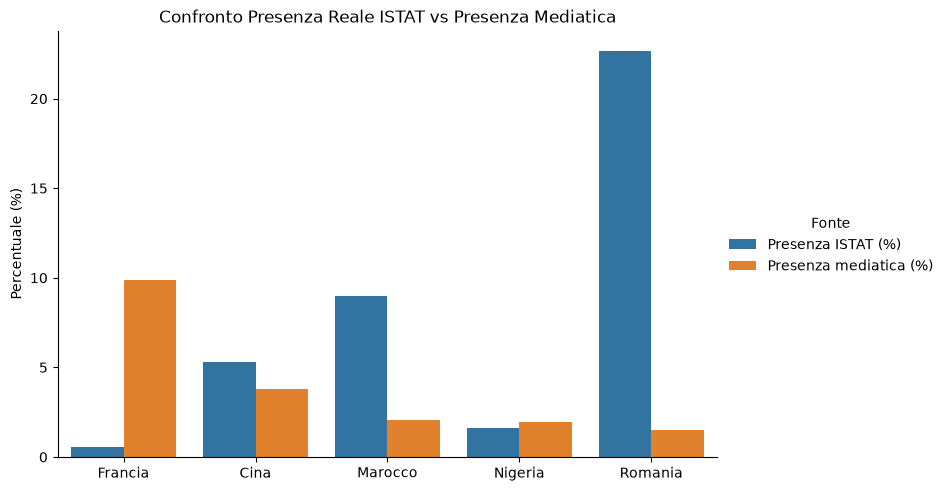

In [ ]:
df_confronto = pd.merge( # uniamo i DataFrame delle percentuali (articoli e ISTAT)
    df_risultati_nazionalita,
    df_media_percentuale,
    on = "Stato di cittadinanza"
)
df_grafico = pd.melt( # creiamo il DataFrame da utilizzare poi per il grafico
    df_confronto,
    id_vars= ["Stato di cittadinanza"],
    value_vars= ["Presenza ISTAT (%)", "Presenza mediatica (%)"],
    var_name= "Fonte",
    value_name= "Percentuale",
)
g = sns.catplot( # creiamo il grafico
    data=df_grafico, kind="bar",
    x="Stato di cittadinanza", y="Percentuale",
    hue="Fonte", aspect=1.5,
)
g.set_axis_labels("", "Percentuale (%)") # definiamo le etichette
plt.title("Confronto Presenza Reale ISTAT vs Presenza Mediatica")

grafici_dir = "output/domanda_1/grafici"
os.makedirs(grafici_dir, exist_ok=True) # assicura che la cartella esista
g.savefig(os.path.join(grafici_dir, "grafico_confronto_ISTAT_media.png"), bbox_inches="tight") # salviamo il grafico in una cartella
plt.show()

## Grafico Indice di Rappresentazione

Il presente grafico lineare segue invece l'andamento della rappresentazione di ciascuna nazionalità nel quinquennio 2014-2018.
Si è impostata una linea tratteggiata all'altezza del numero 1 per rendere visibile la linea sopra la quale vi è una sovra-rappresentazione delle comunità e sotto la quale si ha una sotto-rappresentazione di queste ultime.

Da un primo sguardo generale si nota come la Francia si distanzi notevolmente dalle altre nazionalità. Per questa ragione, è stato inoltre necessario modificare il grafico impostando una scala logaritmica. Se non avessimo agito in questo modo, le linee che costituiscono le 4 nazionalità più in basso sarebbero rimaste "schiacciate" nella parte inferiore, rendendo impossibile analizzare il grafico risultante.

Possiamo sostenere che i risultati osservabili in questo grafico sono coerenti con i risultati ottenuti nel grafico precedente. In particolare:
- **Francia**: la Francia è l'unica eccessivamente sovra-rappresentata, elemento che poteva essere intuito nel grafico precedente, dove la presenza mediatica era molto maggiore della presenza reale francese.
- **Cina**: la Cina ha un indice di rappresentazione pari a 0.99 nel 2014, che cala negli anni successivi ma senza subire grandi variazioni.
- **Marocco**: il Marocco si trova in una posizione inferiore rispetto alla Cina e superiore alla Romania, in una condizione di sotto-rappresentazione con un leggero picco positivo nel 2015.
- **Nigeria**: la Nigeria è la nazionalità più vicina alla soglia d'equilibrio con lievi oscillazioni sopra e sotto l'indice.
- **Romania**: la Romania è la più sotto-rappresentata di tutte le comunità, nonché, secondo i dati raccolti precedentemente, la più presente sul territorio italiano. Si può addirittura osservare un picco negativo nell'anno 2016.

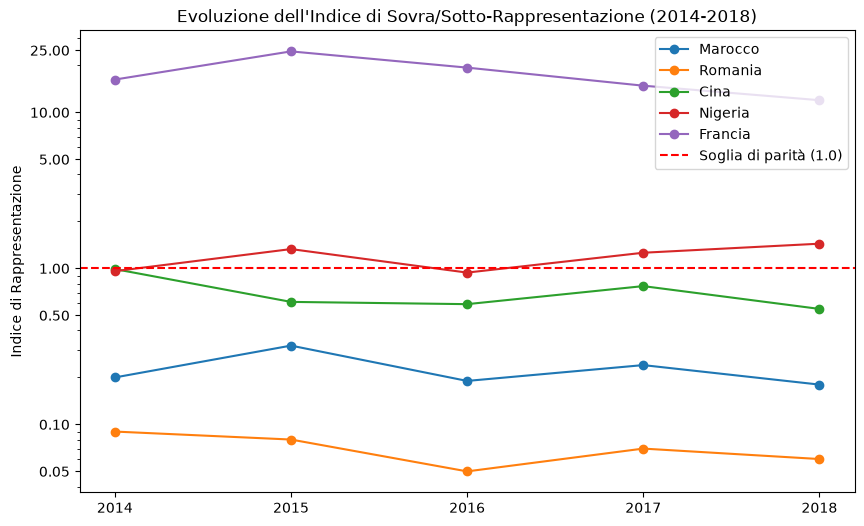

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
anni = [2014, 2015, 2016, 2017, 2018]

for nazionalita in paesi_selezionati:
    df_paese = tabella_indice_pivot[tabella_indice_pivot["Stato di cittadinanza"] == nazionalita] # crea una sola riga con il paese di turno
    valori = df_paese[anni].iloc[0] # seleziona i dati dei 5 anni per la nazionalità corrente
    ax.plot(anni, valori, "o-", label = nazionalita)

ax.axhline(y=1.0, color="red", linestyle="--", label = "Soglia di parità (1.0)")
ax.set_title("Evoluzione dell'Indice di Sovra/Sotto-Rappresentazione (2014-2018)")
ax.set_xlabel("")
ax.set_ylabel("Indice di Rappresentazione")
ax.legend()

ax.set_yscale("log") # modifico l'asse y con valori logaritmici
ax.set_xticks(anni) # tolgo i decimali agli anni
ax.set_yticks([0.05, 0.1, 0.5, 1, 5, 10, 25]) # Scegliamo i valori chiave per l'asse y
ax.get_yaxis().set_major_formatter(ticker.ScalarFormatter()) # forziamo l'asse y ad avere numeri senza notazione esponenziale

grafici_dir1 = "output/domanda_1/grafici"
os.makedirs(grafici_dir1, exist_ok=True)  # assicura che la cartella esista
fig.savefig(os.path.join(grafici_dir1, "evoluzione_indice.png"), bbox_inches="tight")
plt.show()

## Interpretazione finale dei risultati

L'incrocio tra la presenza demografica reale e l'esposizione mediatica su *La Repubblica* nel quinquennio 2014-2018 porta alla luce due fenomeni sociologici distinti riguardo alla narrazione dell'immigrazione in Italia.

- **Il paradosso del gruppo di controllo**: la Francia, inserita nello studio come gruppo di controllo, restituisce il dato più anomalo in assoluto.
Come visibile nel primo grafico, a fronte di una presenza demografica media pari allo 0.57%, la sua copertura mediatica arriva al 9.86% con un **indice di sovra-rappresentazione** compreso tra 11.97 e 24.60.

    **Possibile interpretazione**: una spiegazione plausibile è che la Francia venga citata all'interno degli articoli di giornale non in riferimento diretto a temi che coinvolgono soggettività migranti, quanto piuttosto in contesti giuridico-politici. Secondo questa ipotesi, si potrebbe sostenere come l'ambito giornalistico tenda a trattare temi quali l'immigrazione non dal punto di vista dei soggetti coinvolti, ma da un punto di vista istituzionale che vede tali soggetti come "emergenze" da gestire.

    Tale interpretazione sarà da verificarsi analizzando i rispettivi frame semantici legati alle nazionalità in questione.

- **L'invisibilità della maggioranza**: la Romania, come abbiamo già visto, rappresenta il caso opposto a quello francese.
Nonostante costituisca la comunità straniera più popolosa in Italia con una presenza demografica media del 22.65%, la sua presenza mediatica negli articoli che trattano di immigrazione è la più bassa di tutte (1.53%) con un **indice di sotto-rappresentazione** pari a 0.1.

    **Possibile interpretazione**: questo fenomeno potrebbe essere spiegato con una maggiore integrazione di questa comunità rispetto alle altre e una normalizzazione di tale presenza sul suolo nazionale che porterebbe la comunità a smettere di "fare notizia" e scomparire dal frame narrativo dell'immigrazione. Inoltre, l'invisibilità mediatica potrebbe legarsi anche al tipo di mansioni lavorative prevalentemente svolte da tale comunità (come il lavoro di cura), storicamente meno riconosciute a livello istituzionale e mediatico.

    Anche questa interpretazione potrà essere verificata più nel dettaglio successivamente.

# Seconda questione: In prossimità di alcuni eventi rilevanti nell'arco temporale 2014-2018, come varia la rappresentazione delle 5 nazionalità scelte, all'interno degli articoli?

## Scelta degli eventi:

Scegliamo gli eventi che vogliamo mettere a confronto con la presenza mediatica delle nazionalità: gli attentati di Parigi (novembre 2015), la sparatoria di Macerata (febbraio 2018) e le elezioni politiche (marzo 2018). Non abbiamo incluso i flussi migratori tra gli eventi da studiare perchè, pur essendo di grande rilevanza nel periodo analizzato, non risulta possibile isolare una sola nazionalità negli articoli che trattano questi eventi. Per ciascuno dei tre eventi scelti registriamo anno e mese, che useremo nella cella successiva per individuare la posizione esatta sul grafico. Costruiamo quindi una lista che contiene un dizionario per ognuno dei tre eventi. Ogni dizionario ha quattro chiavi: la data, il nome dell'evento, l'anno e il mese.
L'eventuale aumento della rappresentazione mediatica di una o più nazionalità in prossimità di questi eventi verrà analizzato dopo aver realizzato il grafico e calcolato i relativi valori numerici.

In [ ]:
# lista degli eventi da studiare e marcare sul grafico
eventi = [
    {"data": "2015-11-13", "evento": "Attentati di Parigi", "anno": 2015, "mese": 11},
    {"data": "2018-02-03", "evento": "Sparatoria di Macerata", "anno": 2018, "mese": 2},
    {"data": "2018-03-04", "evento": "Elezioni politiche", "anno": 2018, "mese": 3},
]

## Presenza mediatica delle nazionalità, mese per mese

Calcoliamo, per ciascuno dei 60 mesi tra gennaio 2014 e dicembre 2018, la percentuale di articoli "di immigrazione" che menzionano ciascuna delle cinque nazionalità selezionate.

Per farlo, scorriamo i dati su quattro cicli for annidati: prima ogni **anno** dal 2014 al 2018, poi, per ogni anno, ogni **mese**, poi, per ogni mese, ogni **nazionalità**, e infine, per ogni nazionalità, tutti gli **articoli** di quel mese, contando quelli pertinenti tramite la funzione conteggio() definita precedentemente.

Inseriamo un contatore che aumenta di 1 a ogni iterazione, per numerare progressivamente i mesi da 0 (gennaio 2014) a 59 (dicembre 2018): questo numero ci servirà per posizionare correttamente i dati sul grafico. Inoltre, se il mese che stiamo analizzando corrisponde al mese in cui ha avuto luogo uno dei tre eventi definiti nella cella precedente, ne salviamo subito l'indice temporale, così non dovremo ricercarlo separatamente più avanti.

Ogni risultato calcolato (anno, mese, indice temporale, nazionalità e percentuale) viene salvato come un dizionario, contenuto in una lista, e alla fine trasformato in un DataFrame Pandas (`df_media_mensile`), che useremo sia per il grafico sia per l'analisi numerica successiva.

In [ ]:
risultati_per_mese = []  # lista vuota dove accumuleremo un dizionario di risultati per ogni combinazione anno-mese-nazionalità
indice_tempo_corrente = 0  # contatore che sale di 1 ogni mese, partendo da gennaio 2014 (indice 0)

for anno in range(2014, 2019):  # scorriamo un anno alla volta
    for mese in range(1, 13):  # per ogni anno, scorriamo ogni mese

        # se questo mese corrisponde a uno degli eventi, ne salviamo l'indice_tempo
        for evento in eventi:
            if evento["anno"] == anno and evento["mese"] == mese:
                evento["indice_tempo"] = indice_tempo_corrente

        # filtriamo df_immigrazione tenendo solo le righe (articoli) che appartengono a un determinato anno e mese
        df_imm_mese = df_immigrazione[
            (df_immigrazione["Anno"] == anno) & (df_immigrazione["Mese"] == mese)
        ]

        tot_imm_mese = len(df_imm_mese)  # quanti articoli di immigrazione ci sono in uno specifico mese
        # controlliamo che il mese non sia vuoto
        if tot_imm_mese > 0:

            # per ogni mese, scorriamo tutte le nazionalità
            for nazionalita, varianti_morf in dizionario_nazionalita.items():

                articoli_pertinenti = 0  # quanti articoli di questo mese parlano di questa nazionalità

                # scorriamo un articolo alla volta
                for tokens in df_imm_mese["token_filtrati"]:
                    if conteggio(tokens, varianti_morf):  # se l'articolo menziona la nazionalità (escludendo i falsi positivi), incrementiamo il contatore
                        articoli_pertinenti += 1

                # percentuale di articoli di questo mese che parlano di questa nazionalità, rispetto al totale di articoli di immigrazione di quel mese
                presenza = (articoli_pertinenti / tot_imm_mese) * 100

                # salviamo il risultato come un dizionario con le informazioni, incluso l'indice temporale progressivo
                risultati_per_mese.append({
                    "Anno": anno,
                    "Mese": mese,
                    "indice_tempo": indice_tempo_corrente,
                    "Stato di cittadinanza": nazionalita,
                    "Presenza mediatica (%)": round(presenza, 2)  # arrotondiamo a 2 decimali
                })

        indice_tempo_corrente += 1  # aumentiamo il contatore di 1

# trasformiamo la lista di dizionari in un DataFrame Pandas
df_media_mensile = pd.DataFrame(risultati_per_mese)

df_media_mensile.head(10)

,Anno,Mese,indice_tempo,Stato di cittadinanza,Presenza mediatica (%)
0,2014,1,0,Marocco,0.00
1,2014,1,0,Romania,1.01
2,2014,1,0,Cina,5.05
3,2014,1,0,Nigeria,0.00
4,2014,1,0,Francia,7.07
5,2014,2,1,Marocco,0.00
6,2014,2,1,Romania,3.33
7,2014,2,1,Cina,1.11
8,2014,2,1,Nigeria,2.22
9,2014,2,1,Francia,6.67


## Visualizzazione tramite line chart
Realizziamo un grafico con i dati ottenuti in precedenza: una linea per ciascuna delle cinque nazionalità, con il tempo sull'asse x e la percentuale di presenza mediatica sull'asse y, realizzate con `ax.plot()`.

Creiamo anche, sempre con `ax.plot()`, tre linee verticali tratteggiate grigie (da zero fino al valore massimo osservato nei dati), per marcare i tre eventi che abbiamo deciso di studiare. Questo ci permette di verificare visivamente se le variazioni nelle curve coincidano con le date degli eventi. Assegnando un'etichetta (label) sia alle linee delle nazionalità sia a quelle degli eventi, riusciamo a mostrarle tutte insieme in un'unica legenda.

Dopodichè costruiamo etichette leggibili per l'asse orizzontale: dato che l'indice temporale è solo un numero progressivo, dobbiamo ricostruire a quale anno e mese corrisponde ciascuna posizione. Questo è possibile utilizzando gli operatori aritmetici di divisione intera e resto: la divisione intera ci permette di determinare a quale anno appartiene ciascun indice (anno = 2014 + pos // 12); il resto ci permette di ricavare il mese corrispondente (mese = pos % 12 + 1). Usiamo inoltre una struttura if/else per aggiungere uno zero davanti ai mesi che hanno una sola cifra (ad esempio "02" invece di "2"), in modo che tutte le etichette risultino uniformi sul grafico.

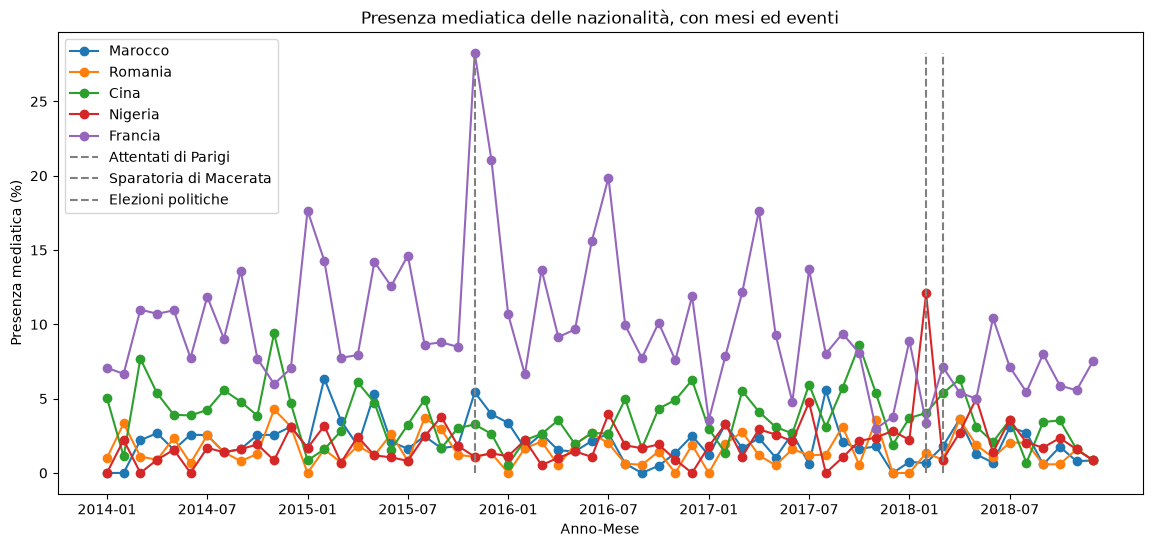

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 6))  # creiamo una figura che copra 60 mesi sull'asse x

# disegniamo una linea per ogni nazionalità: filtriamo df_media_mensile tenendo solo le
# righe di quella nazionalità, le ordiniamo per indice_tempo, e le disegniamo con ax.plot
for nazionalita in paesi_selezionati:
    sotto_df = df_media_mensile[df_media_mensile["Stato di cittadinanza"] == nazionalita]
    sotto_df = sotto_df.sort_values("indice_tempo")
    ax.plot(
        sotto_df["indice_tempo"],
        sotto_df["Presenza mediatica (%)"],
        "o-",
        label=nazionalita
    )

# calcoliamo il valore massimo reale nei dati, per sapere quanto devono essere alte
# le linee verticali degli eventi
valore_massimo = df_media_mensile["Presenza mediatica (%)"].max()

# disegniamo una linea verticale tratteggiata per ciascun evento
for evento in eventi:
    x = evento["indice_tempo"]
    ax.plot(
        [x, x],
        [0, valore_massimo],
        linestyle="dashed",
        color="gray",
        label=evento["evento"]
    )

# mettiamo un'etichetta ogni 6 mesi sull'asse x
posizioni_ticks = list(range(0, 60, 6))
etichette_ticks = []

for pos in posizioni_ticks:
    anno = 2014 + pos // 12
    mese = pos % 12 + 1
    if mese < 10:
        mese_testo = "0" + str(mese)
    else:
        mese_testo = str(mese)
    etichette_ticks.append(f"{anno}-{mese_testo}")

ax.set_xticks(posizioni_ticks, etichette_ticks)
ax.set_xlabel("Anno-Mese")
ax.set_ylabel("Presenza mediatica (%)")
ax.set_title("Presenza mediatica delle nazionalità, con mesi ed eventi")
ax.legend()

#salviamo il grafico in una cartella a parte
grafici_dir2 = "output/domanda_2/grafici"
os.makedirs(grafici_dir2, exist_ok=True) # assicura che la cartella esista
fig.savefig(os.path.join(grafici_dir2, "presenza_mesi_eventi.png"), bbox_inches="tight")

plt.show()



## Quantificazione dell'effetto di ciascun evento

Traduciamo in valori numerici precisi ciò che il grafico ha mostrato. Per ciascuna delle 15 combinazioni possibili (combinando i tre eventi e le cinque nazionalità), prendiamo come riferimento la percentuale media dei sei mesi precedenti all'evento. Questo valore base ci serve perchè rappresenta il livello di presenza mediatica che consideriamo come valore "normale" o di riferimento prima dell'evento. Lo calcoliamo selezionando dal DataFrame `df_media_mensile` i dati relativi alla nazionalità e all'intervallo temporale considerati e applicando `.mean()` alle percentuali dei sei mesi. Successivamente individuiamo, per la stessa nazionalità, la percentuale relativa al mese in cui si è verificato l'evento e utilizziamo `.iloc[0]` per estrarne il valore. Il rapporto tra questi due valori ci mostra di quanto è aumentata (o eventualmente diminuita) l'attenzione mediatica su una determinata nazionalità in coincidenza con uno degli eventi selezionati.

Un accorgimento importante riguarda le elezioni politiche del 2018. La sparatoria di Macerata è avvenuta nel mese immediatamente precedente alle elezioni e rientrerebbe quindi nei sei mesi utilizzati per costruire il valore di riferimento. Per evitare che la presenza mediatica associata a un evento molto vicino temporalmente influenzi la base di confronto dell'evento successivo, escludiamo esplicitamente il mese di Macerata dal calcolo della media relativa alle elezioni. Salviamo quindi in una variabile a parte (`indice_macerata`) l'indice temporale della sparatoria di Macerata, e poi, con un confronto booleano (`!= indice_macerata`), filtriamo il sottoinsieme di dati usato per calcolare la media dei sei mesi precedenti alle elezioni: in questo modo, se quel mese specifico ricade nella finestra dei sei mesi, viene scartato prima del calcolo di `.mean()`. In questo modo i due eventi vengono trattati separatamente.

Inseriamo anche un controllo che fa sì che il rapporto venga calcolato solamente quando sono disponibili sia il valore del mese dell'evento sia la media dei mesi precedenti e quando quest'ultima è diversa da zero, per evitare una divisione non valida.

Per ogni combinazione di evento e nazionalità salviamo infine le informazioni rilevanti (evento, nazionalità, media dei sei mesi precedenti, percentuale nel mese dell'evento e rapporto calcolato) in un dizionario. I dizionari vengono raccolti in una lista e successivamente trasformati in un DataFrame Pandas, `df_quantificazione`. Questa tabella ci permette di confrontare sistematicamente le variazioni osservate per le diverse nazionalità in relazione ai diversi eventi.

In [ ]:
# per ogni evento, confrontiamo il valore "base" con il valore del mese dell'evento
# otteniamo una tabella con i 3 eventi e le 5 nazionalità

indice_macerata = eventi[1]["indice_tempo"]  # indice di Macerata, da escludere dalla base delle elezioni

risultati_quantificazione = []  # lista di dizionari

for evento in eventi:

    # definiamo il periodo "base" (la media dei 6 mesi precedenti)
    indice_evento = evento["indice_tempo"]
    inizio_base = indice_evento - 6
    fine_base = indice_evento - 1

    # filtriamo df_media_mensile tenendo solo le righe di questa nazionalità
    for nazionalita in paesi_selezionati:
        sotto_df = df_media_mensile[df_media_mensile["Stato di cittadinanza"] == nazionalita]

        # calcoliamo la media dei valori nel periodo base
        df_base = sotto_df[
            (sotto_df["indice_tempo"] >= inizio_base) &
            (sotto_df["indice_tempo"] <= fine_base)
        ]

        # escludiamo dalla base l'eventuale mese di un altro evento che ricade nella finestra
        df_base = df_base[df_base["indice_tempo"] != indice_macerata]

        media_base = df_base["Presenza mediatica (%)"].mean()

        # prendiamo il valore specifico del mese dell'evento
        df_evento = sotto_df[sotto_df["indice_tempo"] == indice_evento]

        if len(df_evento) > 0:
            valore_evento = df_evento["Presenza mediatica (%)"].iloc[0]
        else:
            valore_evento = None

        # calcoliamo il rapporto
        if valore_evento is not None and media_base > 0:
            rapporto = valore_evento / media_base

            risultati_quantificazione.append({
                "Evento": evento["evento"],
                "Nazionalità": nazionalita,
                "Media base (%)": round(media_base, 2),
                "Mese evento (%)": round(valore_evento, 2),
                "Rapporto": round(rapporto, 2)
            })

df_quantificazione = pd.DataFrame(risultati_quantificazione)
df_quantificazione

,Evento,Nazionalità,Media base (%),Mese evento (%),Rapporto
0,Attentati di Parigi,Marocco,2.50,5.43,2.17
1,Attentati di Parigi,Romania,2.07,1.09,0.53
2,Attentati di Parigi,Cina,3.20,3.26,1.02
3,Attentati di Parigi,Nigeria,1.85,1.09,0.59
4,Attentati di Parigi,Francia,11.22,28.26,2.52
5,Sparatoria di Macerata,Marocco,1.96,0.67,0.34
6,Sparatoria di Macerata,Romania,1.41,1.34,0.95
7,Sparatoria di Macerata,Cina,4.73,4.03,0.85
8,Sparatoria di Macerata,Nigeria,1.77,12.08,6.82
9,Sparatoria di Macerata,Francia,6.85,3.36,0.49


## Conclusioni sull'analisi degli eventi

I dati raccolti nella tabella permettono di leggere in modo preciso quanto osservato nel grafico, distinguendo i casi in cui un evento ha davvero coinciso con un aumento della presenza mediatica di una nazionalità da quelli in cui l'effetto è debole o assente.

**Attentati di Parigi → Francia e Marocco**: entrambe le nazionalità mostrano un aumento (rapporti di 2,52 e 2,17 rispettivamente). Per questo doppio aumento si può ipotizzare una spiegazione: alcuni responsabili degli attentati dell'11/2015 erano cittadini belgi di origine marocchina, il che spiega perché l'evento abbia coinvolto anche il Marocco oltre alla Francia.

**Sparatoria di Macerata → Nigeria**: è il segnale più forte e netto di tutta l'analisi. La presenza mediatica di persone nigeriane passa da una media "base" dell'1,77% nei sei mesi precedenti al 12,08% nel mese dell'evento, un rapporto di 6,82 volte. Nessun'altra combinazione evento-nazionalità si avvicina a questo valore. È un caso in cui un singolo fatto di cronaca produce un effetto immediato e circoscritto a una sola nazionalità.

**Elezioni politiche → tutte le nazionalità**: qui i risultati non mostrano un pattern chiaro. I rapporti oscillano tra 0,42 (Nigeria) e 1,44 (Marocco), quindi vicini al valore di "nessun cambiamento" (rapporto 1). Non emerge un aumento delle menzioni delle cinque nazionalità in corrispondenza delle campagne elettorali. Una possibile spiegazione è che la retorica elettorale, quando affronta il tema dell'immigrazione, tenda a usare termini generici ("immigrati", "clandestini"), invece di nominare esplicitamente nazionalità specifiche, rendendo l'eventuale effetto invisibile a un'euristica come la nostra, basata sul riconoscimento di parole legate a singole nazionalità. Abbiamo deciso di includere anche questo risultato, nonostante andasse contro le nostre aspettative, per mostrare come invece i dati non supportino l'ipotesi che le campagne elettorali producano, di per sé, un aumento generalizzato delle menzioni di specifiche nazionalità.

## Salvataggio DataFrame e grafici
Salviamo le tabelle e il grafico nella cartella generale `output`.
- Le **tabelle** vengono salvate nella cartella tabelle all'interno della cartella `domanda_2`.
- Il **grafico** è stato salvato (nella relativa cella) nella cartella grafici all'interno della cartella `domanda_2`.

In [ ]:
output_dir2 = "output/domanda_2/tabelle"
os.makedirs(output_dir2, exist_ok=True) # assicura che la cartella esista

# Presenza mediatica mensile
df_media_mensile.to_csv(os.path.join(output_dir2, "presenza_mediatica_mensile.csv"), index=False, encoding="utf-8-sig")

# Quantificazione dell'effetto di ciascun evento
df_quantificazione.to_csv(os.path.join(output_dir2, "quantificazione_effetto_eventi.csv"), index=False, encoding="utf-8-sig")

# Terza questione: Quando si parla di specifiche nazionalità razzializzate, quali contesti o parole chiave vengono associati più frequentemente?

## Analisi del lessico per nazionalità

### Lista delle parole da escludere

Per analizzare il lessico associato alle diverse nazionalità, abbiamo innanzitutto costruito una lista di parole da escludere perché poco informative ai fini dell'analisi. Oltre alle varianti morfologiche delle nazionalità, abbiamo rimosso termini temporali, quantità, soggetti e verbi generici, espressioni tipiche del linguaggio giornalistico e altri termini molto frequenti nel corpus ma poco utili per distinguere la rappresentazione delle diverse nazionalità.

Per farlo, abbiamo inizializzato una lista vuota `(parole_da_escludere)` e vi abbiamo aggiunto prima le diverse varianti delle nazionalità contenute in `dizionario_nazionalita`. Successivamente, i termini poco informativi sono stati organizzati in categorie tematiche e poi riuniti nella stessa lista attraverso dei cicli `for`. Il controllo `if parola not` in `parole_da_escludere` ha permesso di evitare l'inserimento di termini duplicati.

Non abbiamo preso in considerazione le parole italiane più comuni perchè sono già state escluse precedentemente come stopwords.


In [ ]:
# Inizializziamo la lista delle parole da escludere

parole_da_escludere = []

# Aggiungiamo le varianti delle nazionalità
for varianti in dizionario_nazionalita.values():
    for parola in varianti:
        if parola not in parole_da_escludere:
            parole_da_escludere.append(parola)

# Definiamo le categorie di termini irrilevanti
termini_temporali = {
    "anno", "anni", "mese", "mesi", "giorno", "giorni", "ora", "ore", "verso", "fino", "momento", "2013", "2014", "2015", "2016", "ex",
    "ieri", "oggi", "domani", "scorso", "scorsa", "fine", "tempo", "volta", "dove", "quando", "ancora", "mai", "già", "così", "sia", "contro", "proprio", "oltre", "mentre", "sotto",}

numeri_e_quantita = {
    "due", "tre", "quattro", "cinque", "sei", "sette", "otto", "nove", "dieci", "10", "15", "30",
    "cento", "mila", "milioni", "euro", "primo", "prima", "secondo", "meta", "parte", "grande", "quanto", "circa", "totale", "numero", "molti", "ultimi",}

soggetti_generici = {
    "uomo", "donna", "persone", "persona", "gente", "ragazzo", "ragazzi", "donne", "bambini", "lui", "lei", "suoi", "quel", "alcuni", "qualche", "punto", "io", "mia", "mio", "soprattutto", "nostro", "nostra", "insieme", "stesso", "quale",
    "gruppo", "nome", "vita", "casa", "strada", "via", "qui", "città", "posto", "mondo", "tutti", "tutte", "tutto", "molto", "altre", "altro", "altra", "altri", "ogni", "cosa", "noi", "nord", "quasi", "nuovo", "nuova",}

verbi_generici = {
    "detto", "fatto", "sembra", "trova", "stare", "andare", "fare", "dire", "fu", "deve", "viene", "nati",
    "posto", "stato", "stati", "avere", "essere", "visto", "preso", "trovato", "ho", "può", "sarà", "sta", "abbiamo", "siamo", "aver", "is", "sarebbe"}

gergo_giornalistico = {
    "repubblica", "foto", "video", "notizia", "articolo", "cronaca",
    "storia", "caso", "modo", "sempre", "solo", "poi", "dopo", "prima"}

termini_generici = {
    "immigrazione", "migranti", "immigrati", "straniero", "stranieri", "cittadini", "italia", "italiani","italiana", "italiano", "roma", "pechino", "paese", "presidente", "governo", "europa", "ue", "europea", "europeo", "paesi", "nazione", "nazionale", "minori", "lavoro", "politica", "centro", "cina", "nigeria", "francia", "parigi", "marocco", "romania"}

# Uniamo tutti i gruppi alla lista principale
gruppi_da_escludere = [
    termini_temporali,
    numeri_e_quantita,
    soggetti_generici,
    verbi_generici,
    gergo_giornalistico,
    termini_generici
]

for gruppo in gruppi_da_escludere:
    for parola in gruppo:
        if parola not in parole_da_escludere:
            parole_da_escludere.append(parola)

### Calcolo delle frequenze lessicali per nazionalità

Per ciascuna nazionalità abbiamo selezionato gli articoli in cui compare almeno una delle relative varianti morfologiche. Per farlo, abbiamo utilizzato un ciclo `for` che scorre le nazionalità e le rispettive varianti contenute in `dizionario_nazionalita`.
Per ogni nazionalità abbiamo quindi analizzato la colonna `token_filtrati` del dataframe `df_immigrazione`. La funzione `conteggio()` ha permesso di verificare se, tra i token di ciascun articolo, è presente almeno una delle varianti morfologiche considerate e quindi se l'articolo deve essere incluso nell'analisi di quella nazionalità.

Successivamente, dagli articoli selezionati abbiamo eliminato le parole contenute nella lista `parole_da_escludere`: attraverso `if` abbiamo mantenuto solamente i token che non appartengono alla lista e li abbiamo raccolti in `tokens_nazionalita`.
In questo modo abbiamo ottenuto, per ogni nazionalità, un'unica lista contenente il lessico rilevante proveniente da tutti gli articoli associati.

Infine, abbiamo calcolato la frequenza assoluta di ciascuna parola, cioè il numero complessivo di volte in cui compare negli articoli selezionati. Attraverso un ulteriore ciclo `for` abbiamo costruito il dizionario frequenze, nel quale ogni parola costituisce una chiave e il valore associato corrisponde al numero delle sue occorrenze. I risultati sono poi stati salvati nel dizionario `frequenze_per_nazionalita`, utilizzando ciascuna nazionalità come chiave, così da mantenere separati i conteggi e poter confrontare successivamente il lessico maggiormente associato ai diversi stati di cittadinanza.

In [ ]:
# Dizionario per memorizzare i conteggi di ciascuna nazionalità
frequenze_per_nazionalita = {}

for nazionalita, varianti_morf in dizionario_nazionalita.items():
    tokens_nazionalita = []

    # Scorriamo gli articoli dedicati all'immigrazione
    for tokens in df_immigrazione["token_filtrati"]:
        if conteggio(tokens, varianti_morf):

            # Manteniamo solo le parole non presenti nella lista da escludere
            tokens_puliti = []

            for t in tokens:
                if t not in parole_da_escludere:
                    tokens_puliti.append(t)

            tokens_nazionalita = tokens_nazionalita + tokens_puliti

    # Creiamo un dizionario vuoto per contare le parole
    frequenze = {}

    # Contiamo quante volte compare ogni parola
    for parola in tokens_nazionalita:
        if parola in frequenze:
            frequenze[parola] += 1
        else:
            frequenze[parola] = 1

    # Salviamo il dizionario delle frequenze per questa nazionalità
    frequenze_per_nazionalita[nazionalita] = frequenze

### Tabella delle parole più frequenti per nazionalità

A partire dalle frequenze calcolate precedentemente, abbiamo individuato le 10 parole più frequenti associate a ciascuna nazionalità.
Per farlo, abbiamo esaminato con un ciclo `for` i dati contenuti in `frequenze_per_nazionalita` e trasformato, per ogni nazionalità, il relativo dizionario delle frequenze in un DataFrame contenente due colonne: la parola chiave e la sua frequenza assoluta.

Abbiamo poi ordinato le parole in ordine decrescente di frequenza attraverso `sort_values()` e utilizzato `head()` per selezionare solamente le prime 10. A ciascuna parola è stata inoltre assegnata una posizione da 1 a 10 in base alla sua frequenza. Le informazioni relative a nazionalità, posizione, parola e frequenza sono state raccolte in `dati_top_parole` e successivamente trasformate nel DataFrame `df_top_parole`.

Infine, abbiamo riorganizzato i risultati in una tabella comparativa: le righe rappresentano le posizioni dalla 1 alla 10, mentre ogni colonna corrisponde a uno degli stati di cittadinanza contenuti in `paesi_selezionati`.
Per ciascuna nazionalità abbiamo filtrato `df_top_parole` e inserito nella relativa colonna le parole secondo la loro posizione in classifica.
Il risultato finale è stato salvato nel DataFrame `tabella_comparativa`, che ha permesso di confrontare direttamente le parole più frequentemente associate alle diverse nazionalità.

In [ ]:
#TABELLA

top_k = 10
dati_top_parole = []

for nazionalita, frequenze in frequenze_per_nazionalita.items():

    # Trasformiamo il dizionario delle frequenze in un DataFrame
    df_frequenze = pd.DataFrame({
        "Parola chiave": list(frequenze.keys()),
        "Frequenza": list(frequenze.values())
    })

    # Ordiniamo le parole dalla più frequente alla meno frequente
    df_frequenze = df_frequenze.sort_values(
        by="Frequenza",
        ascending=False
    )

    # Prendiamo solo le prime 10 parole
    df_top = df_frequenze.head(top_k)

    posizione = 1

    for indice in df_top.index:

        parola = df_top.loc[indice, "Parola chiave"]
        frequenza = df_top.loc[indice, "Frequenza"]

        dati_top_parole.append({
            "Stato di cittadinanza": nazionalita,
            "Posizione": posizione,
            "Parola chiave": parola,
            "Frequenza": frequenza
        })

        posizione += 1

df_top_parole = pd.DataFrame(dati_top_parole)

# Creiamo la tabella comparativa
tabella_dati = {
    "Posizione": list(range(1, top_k + 1))
}

for nazionalita in paesi_selezionati:

    parole_nazionalita = []

    df_nazionalita = df_top_parole[
        df_top_parole["Stato di cittadinanza"] == nazionalita
    ]

    for indice in df_nazionalita.index:
        parola = df_nazionalita.loc[indice, "Parola chiave"]
        parole_nazionalita.append(parola)

    tabella_dati[nazionalita] = parole_nazionalita

tabella_comparativa = pd.DataFrame(tabella_dati)

# Visualizziamo la tabella
tabella_comparativa

,Posizione,Marocco,Romania,Cina,Nigeria,Francia
0,1,polizia,rispetto,trump,rifugiati,ministro
1,2,rispetto,accoglienza,usa,accoglienza,guerra
2,3,ministro,scuola,uniti,libia,sicurezza
3,4,cittadinanza,detenuti,partito,mare,siria
4,5,terrorismo,rapporto,guerra,asilo,polizia
5,6,asilo,lavoratori,rispetto,tratta,germania
6,7,sicurezza,figli,legge,macerata,sinistra
7,8,comunità,comunità,sicurezza,violenza,partito
8,9,legge,popolazione,sistema,vittime,renzi
9,10,milano,sfruttamento,sinistra,africa,libia


### Visualizzazione delle parole più frequenti

Per facilitare il confronto del lessico giornalistico associato ai diversi stati di cittadinanza, abbiamo rappresentato graficamente la frequenza assoluta delle 10 parole più ricorrenti per ciascuna nazionalità.
Attraverso un ciclo `for` abbiamo considerato separatamente ogni nazionalità presente in `paesi_selezionati` e selezionato da `df_top_parole` solamente le righe corrispondenti, ottenendo così un sottoinsieme di dati `(top_df)` specifico per ciascuno stato di cittadinanza.

Per ogni nazionalità abbiamo quindi creato un grafico a barre utilizzando la funzione `barplot()` di *Seaborn*, riportando sull'asse orizzontale la frequenza assoluta e sull'asse verticale le parole chiave.
Attraverso le funzioni `set_title()`, `set_xlabel()` e `set_ylabel()` abbiamo assegnato infine a ciascun grafico un titolo e le relative etichette degli assi.

Questa rappresentazione ha permesso di osservare più facilmente quali termini ricorrono maggiormente negli articoli associati a ciascuna nazionalità e di confrontare visivamente la loro frequenza.

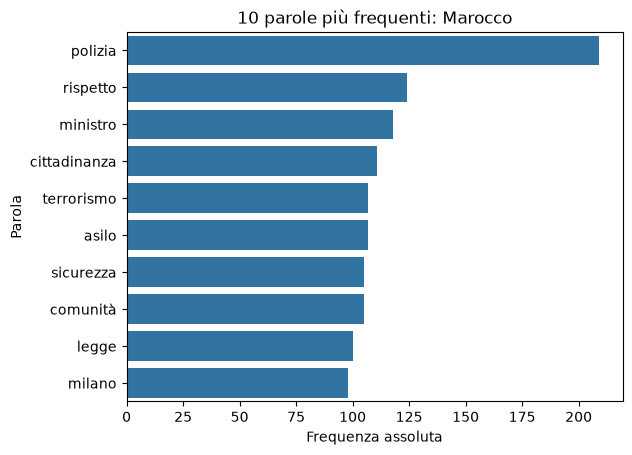

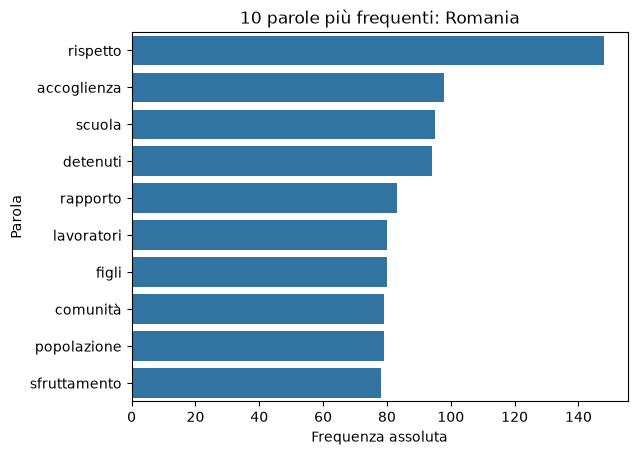

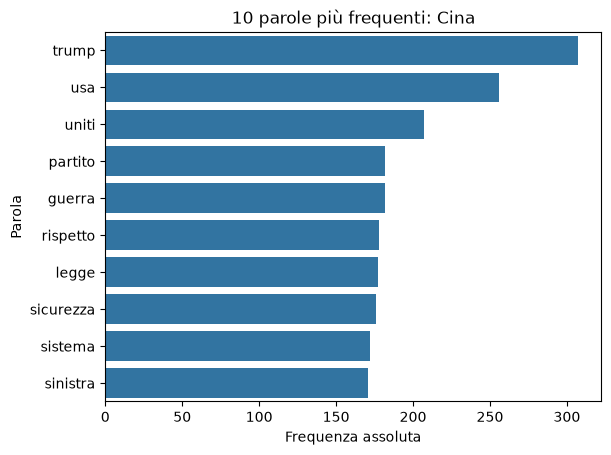

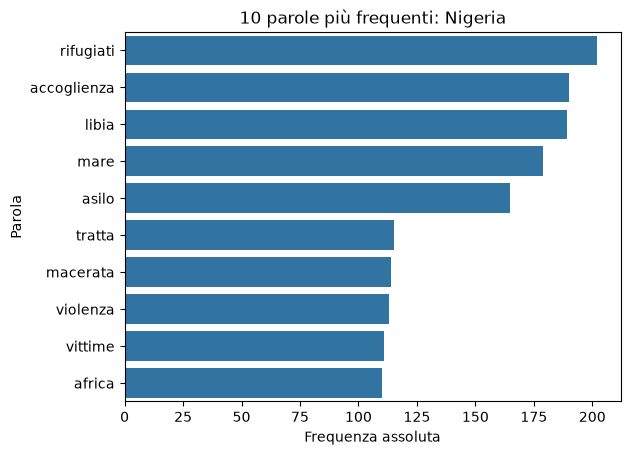

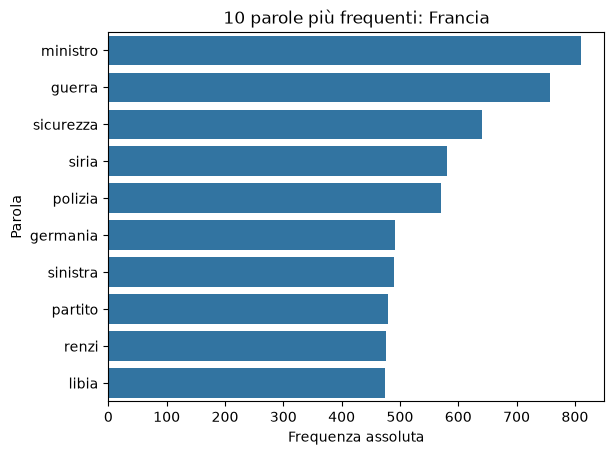

In [ ]:
# CARTELLA IN CUI SALVARE I GRAFICI

grafici_dir3 = "output/domanda_3/grafici"
os.makedirs(grafici_dir3, exist_ok=True)


# GRAFICI DELLE 10 PAROLE PIÙ FREQUENTI

for nazionalita in paesi_selezionati:

    top_df = df_top_parole[
        df_top_parole["Stato di cittadinanza"] == nazionalita
    ]

    fig, ax = plt.subplots()

    sns.barplot(
        data=top_df,
        x="Frequenza",
        y="Parola chiave",
        ax=ax
    )

    ax.set_title(f"10 parole più frequenti: {nazionalita}")
    ax.set_xlabel("Frequenza assoluta")
    ax.set_ylabel("Parola")

    # salviamo il grafico
    nome_file = f"10_parole_piu_frequenti_{nazionalita}.png"

    fig.savefig(
        os.path.join(grafici_dir3, nome_file),
        bbox_inches="tight"
    )

    plt.show()

#### Commento ai risultati

Le parole più frequenti evidenziano profili lessicali differenti tra le nazionalità considerate.

Per il **Marocco** emergono termini che suggeriscono una presenza rilevante di temi legati alla sicurezza e allo status giuridico.
Per la **Romania**, invece, i termini più frequenti rimandano maggiormente a temi sociali, lavorativi e di integrazione.
La **Nigeria** appare soprattutto associata al fenomeno migratorio e alle sue conseguenze.
Per la **Cina** prevalgono invece termini legati al contesto politico e internazionale.
Anche per la **Francia** emerge una forte componente politico-internazionale.

Nel complesso, i risultati suggeriscono quindi che le diverse nazionalità tendono a essere inserite in contesti tematici differenti all'interno del corpus.

### Presenza di categorie lessicali per nazionalità

Per approfondire le modalità con cui le diverse nazionalità vengono rappresentate nel corpus, abbiamo definito cinque macro-categorie semantiche, raccolte nel dizionario `lessico_categorie` e associate a specifici insiemi di parole chiave:

* **Razzismo esplicito e oggettificazione**: comprende termini direttamente stigmatizzanti o espressioni che possono rappresentare le persone straniere come una massa indistinta, invasiva o priva di individualità.
* **Securitizzazione e criminalizzazione**: raccoglie termini che possono associare le persone straniere a criminalità, illegalità, pericolo, disordine o minaccia alla sicurezza.
* **Culturismo ed essenzialismo**: comprende parole che possono ricondurre comportamenti o caratteristiche individuali a presunte caratteristiche fisse e generalizzate della cultura o del gruppo di appartenenza.
* **Utilitarismo e paternalismo**: include termini che possono rappresentare le persone straniere prevalentemente attraverso la loro funzione economica e lavorativa oppure attraverso condizioni di vulnerabilità, bisogno e dipendenza.
* **Deumanizzazione e metafore biologiche**: raccoglie termini che possono descrivere le persone straniere attraverso metafore patologiche o biologiche oppure rappresentarle come un peso o un costo per la collettività.

Le cinque macro-categorie sono state definite per raggruppare termini riconducibili a diverse modalità di rappresentazione negativa o stereotipata delle persone straniere. Le parole sono state assegnate alle categorie in base al loro significato e al tipo di rappresentazione a cui possono contribuire. La classificazione ha uno scopo esplorativo: la presenza di un termine non implica necessariamente una rappresentazione negativa, poiché il suo significato dipende anche dal contesto in cui viene utilizzato.

Per ciascuna nazionalità abbiamo selezionato gli articoli pertinenti utilizzando la funzione `conteggio()`, che verifica la presenza di almeno una delle relative varianti morfologiche. All’interno degli articoli selezionati abbiamo poi controllato se sono presenti termini appartenenti alle cinque categorie lessicali.

Un articolo è associato a una categoria quando contiene almeno una delle relative parole chiave. In questo caso è stato incrementato il contatore della categoria una sola volta per articolo, mentre i singoli termini individuati sono statti salvati in `dettaglio_parole_usate`.

Infine, per ogni nazionalità abbiamo calcolato la percentuale di articoli in cui compare ciascuna categoria rispetto al totale degli articoli pertinenti.
I risultati sono stati raccolti nel DataFrame `df_lessico`, che ha permesso di confrontare la presenza delle diverse categorie lessicali nella rappresentazione giornalistica delle nazionalità considerate.

In [ ]:
# DEFINIZIONE DELLE 5 MACRO-CATEGORIE DI LESSICO

lessico_categorie = {
    "1. Razzismo Esplicito & Oggettificazione": {
        "vu", "cumprà", "zingaro", "zingari", "nomade", "nomadi", "clandestino",
        "clandestini", "ondata", "ondate", "marea", "invasione", "sciame", "flusso", "flussi"},
    "2. Securitizzazione & Criminalizzazione": {
        "baby", "gang", "pusher", "spacciatore", "spacciatori", "criminale", "criminali",
        "degrado", "delinquente", "delinquenti", "sbandato", "sbandati", "delinquenza",
        "irregolare", "irregolari", "fuorilegge", "allarme", "incubo", "terrore",
        "pericolo", "sospetto", "minaccia"},
    "3. Culturismo & Essenzialismo": {
        "incivile", "incivili", "arretrato", "arretrati", "estremista", "estremisti",
        "fanatico", "fanatici", "patriarcale", "patriarcali", "tribale", "tribali",
        "usanza", "usanze", "fondamentalista", "fondamentalisti", "integralista",
        "integralisti", "jihadista", "jihadisti"},
    "4. Utilitarismo & Paternalismo": {
        "bracciante", "braccianti", "invisibile", "invisibili", "disperato", "disperati",
        "miserabile", "miserabili", "sfruttato", "sfruttati"},
    "5. Deumanizzazione & Metafore Biologiche": {
        "piaga", "cancro", "infezione", "parassita", "parassiti", "focolaio", "focolai",
        "carico", "mantenuto", "mantenuti", "contribuenti", "privilegiato", "privilegiati"}
}

# CALCOLO DELLA PRESENZA DELLE CATEGORIE LESSICALI PER OGNI NAZIONALITÀ

risultati_lessico = []
dettaglio_parole_usate = []

for nazionalita, varianti_morf in dizionario_nazionalita.items():

    tot_articoli_nazionalita = 0

    # Inizializziamo i contatori per le 5 categorie
    conteggi_categoria = {cat: 0 for cat in lessico_categorie}

    # Scorriamo gli articoli di immigrazione
    for tokens in df_immigrazione["token_filtrati"]:

        # Controlliamo se l'articolo parla della nazionalità
        if conteggio(tokens, varianti_morf):

            tot_articoli_nazionalita += 1

            # Verifichiamo quali macro-categorie lessicali sono presenti nell'articolo
            for cat_nome, parole_chiave in lessico_categorie.items():

                intersezione = []

                # Cerchiamo manualmente le parole della categoria
                for parola in tokens:

                    if parola in parole_chiave and parola not in intersezione:
                        intersezione.append(parola)

                # Se almeno una parola della categoria è presente
                if len(intersezione) > 0:

                    conteggi_categoria[cat_nome] += 1

                    # Salviamo le parole trovate
                    for parola in intersezione:

                        dettaglio_parole_usate.append({
                            "Stato di cittadinanza": nazionalita,
                            "Categoria lessicale": cat_nome,
                            "Termine": parola
                        })

    # Calcoliamo le percentuali per questa nazionalità
    if tot_articoli_nazionalita > 0:

        riga = {
            "Stato di cittadinanza": nazionalita,
            "Totale Articoli": tot_articoli_nazionalita
        }

        for cat_nome, conteggio_cat in conteggi_categoria.items():

            percentuale = (
                conteggio_cat / tot_articoli_nazionalita
            ) * 100

            riga[cat_nome] = round(percentuale, 2)

        risultati_lessico.append(riga)


# CREAZIONE DEL DATAFRAME RIASSUNTIVO

df_lessico = pd.DataFrame(risultati_lessico)


print(
    "--- TABELLA DI CO-OCCORRENZA LESSICALE "
    "(PERCENTUALE DI ARTICOLI PER CATEGORIA) ---"
)

df_lessico

--- TABELLA DI CO-OCCORRENZA LESSICALE (PERCENTUALE DI ARTICOLI PER CATEGORIA) ---


,Stato di cittadinanza,Totale Articoli,1. Razzismo Esplicito & Oggettificazione,2. Securitizzazione & Criminalizzazione,3. Culturismo & Essenzialismo,4. Utilitarismo & Paternalismo,5. Deumanizzazione & Metafore Biologiche
0,Marocco,214,24.30,43.93,18.69,9.81,12.62
1,Romania,159,23.27,38.99,6.29,13.21,16.98
2,Cina,396,21.46,39.14,6.31,8.59,8.84
3,Nigeria,205,27.32,42.93,8.78,11.71,11.22
4,Francia,1025,21.95,38.34,17.56,7.41,9.27


### Visualizzazione delle categorie lessicali per nazionalità

Per confrontare più facilmente la presenza delle diverse categorie lessicali tra le nazionalità considerate, abbiamo rappresentato graficamente le percentuali calcolate nell’analisi precedente.

A partire da `df_lessico`, abbiamo raccolto per ogni nazionalità e per ciascuna categoria la relativa percentuale di articoli e organizzato questi dati nel nuovo DataFrame `df_lessico_grafico`, in una forma adatta alla rappresentazione grafica.

Abbiamo quindi realizzato la funzione `catplot()` di *Seaborn* per creare un grafico a barre, in cui sull’asse orizzontale sono stati riportati gli stati di cittadinanza e sull’asse verticale la percentuale di articoli. Le diverse categorie lessicali sono state distinte attraverso il parametro `hue`.

Il grafico permette così di confrontare visivamente quanto frequentemente i termini appartenenti alle cinque categorie compaiono negli articoli associati alle diverse nazionalità.

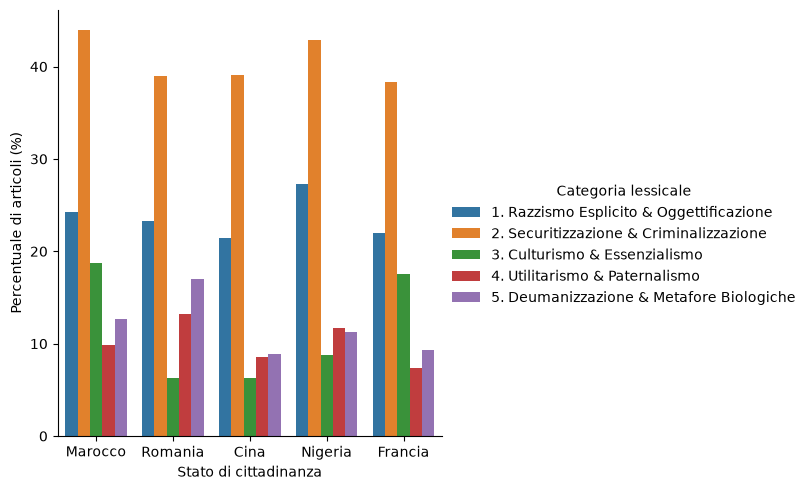

In [ ]:
# CREIAMO IL DATAFRAME PER IL GRAFICO

dati_lessico_grafico = []

for indice in df_lessico.index:

    nazionalita = df_lessico.loc[
        indice,
        "Stato di cittadinanza"]

    for categoria in lessico_categorie:

        percentuale = df_lessico.loc[
            indice,
            categoria]

        dati_lessico_grafico.append({
            "Stato di cittadinanza": nazionalita,
            "Categoria lessicale": categoria,
            "Percentuale": percentuale
        })

df_lessico_grafico = pd.DataFrame(dati_lessico_grafico)

# FACCIAMO IL GRAFICO

g = sns.catplot(
    data=df_lessico_grafico,
    kind="bar",
    x="Stato di cittadinanza",
    y="Percentuale",
    hue="Categoria lessicale")

g.set_axis_labels(
    "Stato di cittadinanza",
    "Percentuale di articoli (%)")


grafici_dir3 = "output/domanda_3/grafici"
os.makedirs(grafici_dir3, exist_ok=True) # assicura che la cartella esista
g.savefig(os.path.join(grafici_dir3, "grafico_categorie_lessicali.png"), bbox_inches="tight") # salviamo il grafico in una cartella

plt.show()

#### Commento ai risultati

Il confronto tra le cinque macro-categorie mostra un andamento piuttosto omogeneo tra le nazionalità. La categoria **Securitizzazione e Criminalizzazione** è infatti la più presente per tutti i gruppi analizzati.
La seconda categoria maggiormente presente è generalmente **Razzismo esplicito e Oggettificazione**.

Le altre categorie risultano meno frequenti e mostrano alcune differenze tra le nazionalità: ad esempio, **Culturismo ed Essenzialismo** è più presente negli articoli relativi a Marocco e Francia, mentre **Utilitarismo e Paternalismo** e **Deumanizzazione e Metafore biologiche** assumono valori relativamente più elevati per la Romania.

Nel complesso, emerge quindi soprattutto la ricorrenza di un lessico riconducibile alla dimensione della **sicurezza e della criminalità**, comune a tutte le nazionalità considerate. Il risultato deve tuttavia essere interpretato in termini di co-occorrenza lessicale: la presenza delle parole appartenenti a una categoria non implica necessariamente che l'articolo utilizzi effettivamente un frame negativo, poiché ciò dipende dal contesto in cui i termini compaiono.

### Parole più frequenti nelle categorie lessicali

Per approfondire quali termini caratterizzano maggiormente le diverse categorie lessicali, abbiamo analizzato le parole individuate per ciascuna combinazione di nazionalità e categoria.

A partire da `dettaglio_parole_usate`, abbiamo selezionato i termini relativi a ogni nazionalità e categoria e contato il numero di articoli in cui ciascun termine compare. Dato che uno stesso termine viene registrato una sola volta all’interno di ciascun articolo, il conteggio indica la sua diffusione tra gli articoli analizzati e non il numero totale di occorrenze della parola.

I risultati sono stati raccolti nel DataFrame `top_parole` e ordinati in base alla frequenza. Infine, per ogni nazionalità abbiamo mostrato i tre termini presenti nel maggior numero di articoli per ciascuna categoria lessicale. Quando non sono stati rilevati termini appartenenti a una determinata categoria, è stata indicata la loro assenza.

In [ ]:
# Calcoliamo le frequenze delle parole per ogni nazionalità e categoria

frequenze_lessico = []

for nazionalita in paesi_selezionati:

    for categoria in lessico_categorie:

        frequenze = {}

        # Scorriamo tutte le parole trovate nelle categorie lessicali
        for elemento in dettaglio_parole_usate:

            if (
                elemento["Stato di cittadinanza"] == nazionalita
                and elemento["Categoria lessicale"] == categoria
            ):

                parola = elemento["Termine"]

                # Contiamo il numero di articoli in cui compare il termine
                if parola in frequenze:
                    frequenze[parola] += 1
                else:
                    frequenze[parola] = 1

        # Salviamo i risultati nella lista
        for parola in frequenze:

            frequenze_lessico.append({
                "Stato di cittadinanza": nazionalita,
                "Categoria lessicale": categoria,
                "Termine": parola,
                "Frequenza": frequenze[parola]
            })


# Trasformiamo i risultati in un DataFrame

top_parole = pd.DataFrame(frequenze_lessico)


# Ordiniamo le parole dalla più frequente alla meno frequente

top_parole = top_parole.sort_values(
    by=["Stato di cittadinanza", "Categoria lessicale", "Frequenza"],
    ascending=[True, True, False]
)


# Mostriamo le prime 3 parole per ogni categoria e nazionalità

for nazion in paesi_selezionati:

    print(f"\n==================== {nazion.upper()} ====================")

    df_nazion = top_parole[
        top_parole["Stato di cittadinanza"] == nazion
    ]

    for cat in lessico_categorie:

        parole_cat = df_nazion[
            df_nazion["Categoria lessicale"] == cat
        ].head(3)

        if len(parole_cat) > 0:

            termini = []

            for indice in parole_cat.index:

                parola = parole_cat.loc[indice, "Termine"]
                frequenza = parole_cat.loc[indice, "Frequenza"]

                termini.append(
                    f"{parola} ({frequenza})"
                )

            termini_str = ", ".join(termini)

            print(f"• {cat}: {termini_str}")

        else:

            print(f"• {cat}: Nessun termine rilevato")


==================== MAROCCO ====================
• 1. Razzismo Esplicito & Oggettificazione: flussi (23), flusso (13), ondata (5)
• 2. Securitizzazione & Criminalizzazione: allarme (19), pericolo (16), minaccia (15)
• 3. Culturismo & Essenzialismo: jihadista (22), jihadisti (20), estremisti (7)
• 4. Utilitarismo & Paternalismo: disperati (7), invisibili (5), disperato (4)
• 5. Deumanizzazione & Metafore Biologiche: carico (14), contribuenti (3), piaga (3)

==================== ROMANIA ====================
• 1. Razzismo Esplicito & Oggettificazione: flussi (13), flusso (9), invasione (7)
• 2. Securitizzazione & Criminalizzazione: pericolo (13), allarme (11), irregolari (9)
• 3. Culturismo & Essenzialismo: jihadisti (2), jihadista (2), estremisti (2)
• 4. Utilitarismo & Paternalismo: braccianti (6), invisibili (5), sfruttati (5)
• 5. Deumanizzazione & Metafore Biologiche: carico (11), contribuenti (5), cancro (3)

==================== CINA ====================
• 1. Razzismo Esplicito &

#### Commento ai risultati

L’analisi mostra che alcune categorie sono caratterizzate da termini ricorrenti in modo abbastanza trasversale tra le nazionalità.

Nella categoria **Razzismo esplicito e Oggettificazione** prevalgono soprattutto *flussi*, *flusso* e *ondata*, mentre nella categoria **Securitizzazione e Criminalizzazione** ricorrono frequentemente termini come *allarme*, *pericolo* e *minaccia*. Per la Nigeria emerge inoltre una maggiore presenza di parole direttamente legate alla criminalità e all’irregolarità, come *criminali* e *irregolari*. La categoria **Culturismo ed Essenzialismo** presenta invece differenze più marcate: per Marocco e Francia risultano particolarmente frequenti *jihadista*, *jihadisti* ed *estremisti*, mentre per le altre nazionalità questi termini compaiono in misura molto più contenuta.Nell’area **Utilitarismo e Paternalismo** ricorrono soprattutto *disperati*, *invisibili* e termini legati allo sfruttamento lavorativo, mentre nella categoria **Deumanizzazione e Metafore Biologiche** il termine più diffuso per tutte le nazionalità è *carico*.

Nel complesso, i risultati mostrano quindi che, pur esistendo alcuni termini comuni alle diverse nazionalità, la composizione interna delle categorie lessicali varia tra i gruppi e contribuisce a evidenziare differenti associazioni tematiche nel corpus.

### Conclusioni analisi del lessico

Per concludere, l’analisi delle 10 parole più frequenti mostra che le diverse nazionalità vengono associate a temi in parte differenti. Il **Marocco** è maggiormente legato a temi di sicurezza e terrorismo, mentre per la **Romania** emergono soprattutto aspetti sociali e lavorativi, attraverso parole come *accoglienza, scuola, lavoratori* e *comunità*. La **Nigeria** è associata principalmente al fenomeno migratorio, con termini come *rifugiati, accoglienza, Libia, mare, asilo* e *tratta*. **Cina e Francia**, invece, compaiono soprattutto in articoli legati alla politica e agli eventi internazionali.

L’analisi delle categorie lessicali completa questo quadro. Per tutte le nazionalità, la categoria più presente è **Securitizzazione e Criminalizzazione**, che compare in circa il 38-44% degli articoli. Il valore più alto si osserva per il **Marocco** (43,93%), seguito dalla **Nigeria** (42,93%). Questo risultato è coerente con la presenza, tra le parole più frequenti, di termini come *polizia, sicurezza, terrorismo* e *violenza*. Il fatto che questa categoria sia la più frequente per tutte le nazionalità è particolarmente interessante: potrebbe indicare che l’associazione con temi di sicurezza e criminalità non riguardi solamente alcuni gruppi specifici, ma rappresenti una caratteristica più generale del modo in cui il tema dell’immigrazione viene trattato nel corpus.

Emergono comunque alcune differenze tra le nazionalità. **Marocco e Francia** presentano una maggiore presenza del lessico legato al **Culturismo ed Essenzialismo**, rispettivamente nel 18,69% e 17,56% degli articoli. Nel caso del Marocco, questo dato si accompagna alla presenza di parole legate al terrorismo e potrebbe riflettere una maggiore attenzione verso aspetti culturali, religiosi o identitari. La **Romania**, invece, si distingue per una maggiore presenza delle categorie **Utilitarismo e Paternalismo** (13,21%) e **Deumanizzazione e Metafore biologiche** (16,98%). Considerando anche la presenza di parole come *lavoratori*, questo potrebbe suggerire una rappresentazione maggiormente legata al ruolo sociale ed economico delle persone di questa nazionalità.

Unendo le due analisi emerge quindi un quadro composto da elementi comuni e differenze specifiche. Da una parte, le 10 parole più frequenti mostrano quali temi vengono maggiormente associati alle diverse nazionalità: migrazione per la Nigeria, lavoro e dimensione sociale per la Romania, sicurezza e terrorismo per il Marocco e politica internazionale per Cina e Francia. Dall’altra, le categorie lessicali permettono di osservare quali cornici linguistiche ricorrono negli articoli. In particolare, la forte presenza della **Securitizzazione e Criminalizzazione** suggerisce l’esistenza di una cornice comune legata ai temi della sicurezza, che si combina però con associazioni tematiche diverse a seconda della nazionalità considerata.

Questi risultati permettono inoltre di riprendere alcune delle ipotesi formulate precedentemente a partire dal confronto tra presenza demografica ed esposizione mediatica. In particolare, il caso della Francia sembra essere coerente con l’ipotesi secondo cui la sua forte sovra-rappresentazione mediatica dipenda soprattutto dalla sua presenza negli articoli come attore politico e istituzionale, piuttosto che come comunità migrante. Tra le parole più frequenti compaiono infatti termini come *ministro, guerra, Siria, Germania, sinistra e Renzi*, che rimandano principalmente a un contesto politico e internazionale.

Anche i risultati relativi alla Romania sembrano in parte coerenti con l’ipotesi di una maggiore normalizzazione della sua presenza nel contesto italiano. Termini come *scuola, lavoratori, figli, comunità e popolazione* rimandano infatti maggiormente a una dimensione sociale, lavorativa e quotidiana, piuttosto che a una dimensione emergenziale. Tuttavia, la maggiore presenza relativa delle categorie Utilitarismo e Paternalismo (13,21%) e Deumanizzazione e Metafore biologiche (16,98%) suggerisce che la minore esposizione mediatica non debba essere interpretata automaticamente come una rappresentazione più positiva.

Nel complesso, quindi, le analisi sembrano suggerire che tra le diverse nazionalità non cambi soltanto il livello di visibilità mediatica, ma anche il tipo di contesto e di narrazione attraverso cui esse diventano visibili.

È tuttavia importante non interpretare automaticamente queste associazioni come prova di una rappresentazione negativa o stereotipata. L’analisi rileva infatti la presenza delle parole, ma non il significato che queste assumono all’interno della frase o dell’articolo. Questo limite è particolarmente evidente per **Cina e Francia**, per le quali molte delle parole più frequenti riguardano la politica e gli eventi internazionali: in questi casi, alcuni termini appartenenti alle categorie lessicali potrebbero descrivere il tema dell’articolo piuttosto che la nazionalità stessa. I risultati permettono quindi di individuare possibili tendenze e associazioni lessicali nella rappresentazione giornalistica, che richiederebbero un’analisi qualitativa del contesto per poter essere interpretate in modo più approfondito.


## Salvataggio DataFrame

In [ ]:
# SALVATAGGIO FILE
output_dir3 = "output/domanda_3/tabelle"
os.makedirs(output_dir3, exist_ok=True) # assicura che la cartella esista

# Parole più frequenti per nazionalità
tabella_comparativa.to_csv(os.path.join(output_dir3, "parole_piu_freq_per_nazionalita.csv"), index=False, encoding="utf-8-sig")

# Presenza categorie lessicali per nazionalità
df_lessico.to_csv(os.path.join(output_dir3, "categorie_lessicali_per_nazionalita.csv"), index=False, encoding="utf-8-sig")

# Conclusioni

In conclusione, le tre analisi mostrano che la rappresentazione mediatica delle cinque nazionalità considerate non rispecchia semplicemente il loro peso demografico nella popolazione straniera residente in Italia, ma appare selettiva e fortemente legata agli eventi e ai contesti giornalistici nei quali le diverse nazionalità vengono citate.

La **prima analisi**, basata sul confronto tra presenza mediatica e dati ISTAT, evidenzia infatti forti differenze tra le comunità. Romania e Marocco, nonostante rappresentino le comunità numericamente più consistenti tra quelle considerate, risultano fortemente sottorappresentate negli articoli, con un indice medio di rappresentazione rispettivamente di 0,07 e 0,23. Anche la Cina risulta complessivamente sottorappresentata, con un indice medio di circa 0,70. La Nigeria presenta invece una situazione più equilibrata, con un indice medio di 1,19 e una tendenza alla sovrarappresentazione negli ultimi anni del periodo analizzato. Il caso più evidente è quello della Francia, che presenta una copertura mediatica molto superiore al proprio peso nella popolazione straniera residente, con un indice medio di circa 17,4. La numerosità di una comunità sul territorio non sembra quindi tradursi direttamente in una maggiore attenzione mediatica.

La **seconda analisi** permette di comprendere meglio come questa visibilità possa variare nel tempo. Alcuni eventi coincidono infatti con aumenti molto marcati della presenza mediatica di specifiche nazionalità. Il caso più evidente è la sparatoria di Macerata, durante la quale la presenza mediatica della Nigeria passa da una media dell’1,77% nei sei mesi precedenti al 12,08% nel mese dell’evento, risultando quasi sette volte superiore. Anche in corrispondenza degli attentati di Parigi si osserva un aumento della presenza della Francia, da 11,22% a 28,26%, e del Marocco, da 2,50% a 5,43%. Al contrario, le elezioni politiche del 2018 non mostrano un aumento generalizzato delle menzioni delle nazionalità considerate. Questo suggerisce che la visibilità mediatica non dipenda soltanto da caratteristiche relativamente stabili, come la presenza demografica, ma possa essere temporaneamente amplificata da specifici fatti di cronaca o avvenimenti politici e internazionali.

La **terza analisi**, dedicata al lessico, aggiunge un ulteriore livello di interpretazione mostrando che, oltre a differire nella quantità di attenzione ricevuta, le nazionalità vengono inserite anche in contesti giornalistici differenti. Il Marocco presenta un lessico che combina riferimenti all’integrazione e alla comunità con temi relativi a sicurezza e terrorismo; la Romania è maggiormente associata a una dimensione sociale, attraverso termini relativi ad accoglienza, scuola, lavoro e comunità; la Nigeria è fortemente collegata al fenomeno migratorio, all’asilo, alle rotte mediterranee e alla vulnerabilità; Cina e Francia compaiono invece soprattutto all’interno di contesti politici e geopolitici.
Nonostante queste differenze, emerge un elemento trasversale: per tutte e cinque le nazionalità la categoria lessicale più presente è quella della **securitizzazione e criminalizzazione**, che compare in circa il 38-44% degli articoli pertinenti. Anche questo risultato deve però essere letto alla luce del contesto complessivo. Nel caso della Nigeria, ad esempio, il lessico della sicurezza convive con parole come *rifugiati, accoglienza, Libia, asilo, tratta* e *vittime*, mentre nel caso della Cina le parole più frequenti comprendono *Trump, USA, guerra* e *partito*. La presenza della stessa categoria lessicale non implica quindi necessariamente una rappresentazione identica: termini riconducibili alla sicurezza possono assumere significati differenti a seconda del frame giornalistico nel quale vengono utilizzati.

Considerando insieme le tre questioni, emerge quindi un quadro più complesso della rappresentazione mediatica. Le nazionalità non sembrano ricevere attenzione in proporzione alla loro effettiva presenza nella popolazione italiana: comunità molto numerose, come quella rumena e marocchina, possono essere relativamente poco visibili, mentre altre, come quella francese, risultano fortemente sovrarappresentate. A questa selettività quantitativa si aggiunge una componente temporale, poiché determinati eventi possono produrre forti aumenti della visibilità di una specifica nazionalità, come osservato soprattutto per la Nigeria in occasione della sparatoria di Macerata. Infine, la dimensione lessicale mostra che essere più o meno presenti negli articoli non è l’unico elemento rilevante: cambia anche il modo e il contesto in cui le diverse nazionalità vengono rappresentate.

In alcuni casi, l’analisi lessicale permette inoltre di rileggere i risultati quantitativi iniziali. La forte sovra-rappresentazione della Francia appare coerente con la sua frequente presenza in contesti politici e geopolitici, suggerendo che la nazionalità venga spesso citata come attore istituzionale più che come comunità migrante. Al contrario, la sotto-rappresentazione della Romania si accompagna a un lessico maggiormente legato alla dimensione sociale, lavorativa e quotidiana, un risultato compatibile con l’ipotesi di una maggiore normalizzazione della sua presenza nel contesto italiano.

I tre livelli di analisi risultano quindi complementari. Nel loro insieme suggeriscono che la rappresentazione giornalistica delle nazionalità considerate dipenda dall’interazione tra le scelte dei media, gli eventi del momento e i diversi modi di raccontare il fenomeno, piuttosto che riflettere semplicemente la composizione della popolazione straniera presente in Italia.

È comunque necessario interpretare questi risultati con cautela. Le analisi individuano associazioni e co-occorrenze, ma non consentono di stabilire rapporti causali. Gli aumenti osservati nei mesi degli eventi indicano una coincidenza temporale, ma non dimostrano da soli che l’evento sia la causa dell’aumento. Allo stesso modo, la presenza di parole appartenenti a una determinata categoria lessicale nello stesso articolo in cui viene citata una nazionalità non permette di affermare che tali termini siano necessariamente riferiti a quella nazionalità. Questo limite è particolarmente importante per Francia e Cina, dato il forte contenuto politico e geopolitico degli articoli associati. I risultati permettono quindi di individuare pattern significativi nella copertura giornalistica, che potrebbero essere approfonditi attraverso analisi più specifiche del contenuto e del contesto in cui i singoli termini vengono utilizzati.

Per concludere, i risultati suggeriscono che la presenza delle diverse nazionalità nel discorso giornalistico sull’immigrazione non rifletta semplicemente la loro presenza demografica sul territorio italiano. La visibilità mediatica sembra dipendere anche dalla loro “notiziabilità”, ovvero dalla possibilità che una determinata nazionalità venga associata a eventi, temi o contesti considerati rilevanti dal punto di vista giornalistico. Questo permette di comprendere sia le differenze nella quantità di copertura ricevuta dalle diverse nazionalità, sia le variazioni osservate nel tempo e i differenti contesti lessicali in cui esse compaiono. La rappresentazione mediatica appare quindi come il risultato di un processo di selezione, nel quale alcune nazionalità diventano maggiormente visibili in relazione a specifici eventi o frame narrativi.

In questa prospettiva, essere numericamente più presenti nella società non significa necessariamente essere più visibili nel discorso mediatico e, allo stesso tempo, una maggiore visibilità non implica necessariamente che una comunità sia il soggetto principale della narrazione.


In [ ]:
# TABELLA RIASSUNTIVA FINALE DELLE TRE ANALISI

riassunto_finale = []

for nazionalita in paesi_selezionati:


    # 1. ARTICOLI PERTINENTI

    df_articoli_nazione = df_risultati_nazionalita[
        df_risultati_nazionalita["Stato di cittadinanza"] == nazionalita]

    articoli_pertinenti = df_articoli_nazione[
        "Articoli pertinenti"].iloc[0]


    # 2. PRESENZA MEDIATICA MEDIA 2014-2018

    df_media_nazione = df_media_annuale[
        df_media_annuale["Stato di cittadinanza"] == nazionalita]

    presenza_media = df_media_nazione[
        "Presenza mediatica (%)"].mean()


    # 3. PRESENZA ISTAT MEDIA 2014-2018

    df_istat_nazione = df_media_percentuale[
        df_media_percentuale["Stato di cittadinanza"] == nazionalita]

    presenza_istat = df_istat_nazione[
        "Presenza ISTAT (%)"].iloc[0]


    # 4. INDICE DI RAPPRESENTAZIONE MEDIO

    df_indice_nazione = df_articoli_istat[
        df_articoli_istat["Stato di cittadinanza"] == nazionalita]

    indice_medio = df_indice_nazione[
        "Indice Rappresentazione"].mean()


    # 5. EVENTO CON MAGGIORE VARIAZIONE

    df_eventi_nazione = df_quantificazione[
        df_quantificazione["Nazionalità"] == nazionalita]

    rapporto_massimo = 0
    evento_principale = ""

    for indice in df_eventi_nazione.index:

        rapporto = df_eventi_nazione.loc[
            indice,
            "Rapporto"]

        if rapporto > rapporto_massimo:

            rapporto_massimo = rapporto

            evento_principale = df_eventi_nazione.loc[
                indice,
                "Evento"]

    rapporto_evento = rapporto_massimo


    # 6. CATEGORIA LESSICALE PIÙ PRESENTE

    df_lessico_nazione = df_lessico[
        df_lessico["Stato di cittadinanza"] == nazionalita]

    categoria_prevalente = ""
    percentuale_categoria = 0

    for categoria in lessico_categorie:

        valore = df_lessico_nazione[
            categoria].iloc[0]

        if valore > percentuale_categoria:
            percentuale_categoria = valore
            categoria_prevalente = categoria

    if categoria_prevalente == "":
        categoria_prevalente = "Nessuna categoria"


    # 7. TRE PAROLE PIÙ FREQUENTI

    df_parole_nazione = df_top_parole[
        df_top_parole["Stato di cittadinanza"] == nazionalita].head(3)

    parole_frequenti = []

    for indice in df_parole_nazione.index:

        parola = df_parole_nazione.loc[
            indice,
            "Parola chiave"]

        parole_frequenti.append(parola)

    parole_frequenti_str = ", ".join(parole_frequenti)


    # SALVIAMO I RISULTATI

    riassunto_finale.append({

        "Stato di cittadinanza": nazionalita,

        "Articoli pertinenti": articoli_pertinenti,

        "Presenza mediatica media (%)":
            presenza_media,

        "Presenza ISTAT media (%)":
            presenza_istat,

        "Indice rappresentazione medio":
            indice_medio,

        "Evento con maggiore variazione":
            evento_principale,

        "Rapporto evento":
            rapporto_evento,

        "3 parole più frequenti":
            parole_frequenti_str,

        "Categoria lessicale prevalente":
            categoria_prevalente
    })


# CREIAMO IL DATAFRAME

df_riassunto_finale = pd.DataFrame(riassunto_finale)

df_riassunto_finale

,Stato di cittadinanza,Articoli pertinenti,Presenza mediatica media (%),Presenza ISTAT media (%),Indice rappresentazione medio,Evento con maggiore variazione,Rapporto evento,3 parole più frequenti,Categoria lessicale prevalente
0,Marocco,214,2.046,8.97,0.226,Attentati di Parigi,2.17,"polizia, rispetto, ministro",2. Securitizzazione & Criminalizzazione
1,Romania,159,1.530,22.65,0.070,Sparatoria di Macerata,0.95,"rispetto, accoglienza, scuola",2. Securitizzazione & Criminalizzazione
2,Cina,396,3.710,5.30,0.702,Elezioni politiche,1.06,"trump, usa, uniti",2. Securitizzazione & Criminalizzazione
3,Nigeria,205,1.966,1.63,1.186,Sparatoria di Macerata,6.82,"rifugiati, accoglienza, libia",2. Securitizzazione & Criminalizzazione
4,Francia,1025,9.800,0.57,17.398,Attentati di Parigi,2.52,"ministro, guerra, sicurezza",2. Securitizzazione & Criminalizzazione


In [ ]:
# SALVATAGGIO FILE
output_dir4 = "output"
os.makedirs(output_dir4, exist_ok=True) # assicura che la cartella esista

# Tabella riassuntiva finale
df_riassunto_finale.to_csv(os.path.join(output_dir4, "tabella_riassuntiva.csv"), index=False, encoding="utf-8-sig")